### Filtering data

In [ ]:
# Mouse
import pandas as pd
import numpy as np
import os

input_file = r"E:\Data\Carrier_protein\Mouse\Second_Batch_Sequencing\thresholds\11012026_analysis\Final_matrix_With_Protein_sample_info_5000.csv"
output_dir = r"E:\Data\Carrier_protein\Mouse\Second_Batch_Sequencing\thresholds\11012026_analysis"

os.makedirs(output_dir, exist_ok=True)

filtered_wide_file = os.path.join(
    output_dir,
    "filtered_barcodes_wide.csv"
)

barcode_by_region_file = os.path.join(
    output_dir,
    "barcodes_by_sample_protein_region.csv"
)

summary_file = os.path.join(
    output_dir,
    "barcode_number_by_sample_protein_region.csv"
)


# Read CSV


df = pd.read_csv(input_file)


df.columns = df.columns.str.strip()

print("Columns in input file:")
print(df.columns.tolist())



region_cols = ["Thalamus", "SNr", "Medulla"]
barcode_col = "Barcode"
protein_col = "Protein"
sample_col = "Sample"

required_cols = (
    region_cols
    + [barcode_col, protein_col, sample_col]
)

missing_cols = [
    col for col in required_cols
    if col not in df.columns
]

if missing_cols:
    raise ValueError(
        f"Missing required columns: {missing_cols}"
    )




df = df.reset_index(drop=True)

df.insert(
    0,
    "barcode_id",
    np.arange(1, len(df) + 1)
)




numeric_cols = region_cols + [barcode_col]

df[numeric_cols] = (
    df[numeric_cols]
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0)
)

# Set Barcode <= 2 to zero


count_cols = ["Thalamus", "SNr", "Medulla", "Barcode"]

df[count_cols] = df[count_cols].mask(
    df[count_cols] <= 2,
    0
)

#  Calculate maximum projection count


df["max_region_count"] = df[region_cols].max(axis=1)


# Filter barcodes
#
# Conditions:
# 1. Barcode > 50
# 2. Barcode > max(Thalamus, SNr, Medulla)


filtered_df = df[
    (df[barcode_col] > 50)
    &
    (df[barcode_col] > df["max_region_count"])
].copy()

print(
    f"\nTotal original barcodes: {len(df)}"
)

print(
    f"Barcodes passing filtering: {len(filtered_df)}"
)




filtered_df = filtered_df.sort_values(
    by=[
        sample_col,
        protein_col,
        barcode_col
    ],
    ascending=[
        True,
        True,
        False
    ]
)




barcode_by_region = filtered_df.melt(
    id_vars=[
        "barcode_id",
        sample_col,
        protein_col,
        barcode_col,
        "max_region_count"
    ],
    value_vars=region_cols,
    var_name="Region",
    value_name="Region_count"
)


#  Remove regions with count = 0


barcode_by_region = barcode_by_region[
    barcode_by_region["Region_count"] > 0
].copy()


barcode_by_region = barcode_by_region.sort_values(
    by=[
        sample_col,
        protein_col,
        "Region",
        barcode_col,
        "Region_count"
    ],
    ascending=[
        True,
        True,
        True,
        False,
        False
    ]
)


barcode_by_region = barcode_by_region[
    [
        "barcode_id",
        sample_col,
        protein_col,
        "Region",
        "Region_count",
        barcode_col,
        "max_region_count"
    ]
]



barcode_summary = (
    barcode_by_region
    .groupby(
        [
            sample_col,
            protein_col,
            "Region"
        ],
        as_index=False
    )
    .agg(
        number_of_barcodes=("barcode_id", "nunique"),
        total_region_counts=("Region_count", "sum"),
        mean_region_count=("Region_count", "mean"),
        median_region_count=("Region_count", "median"),
        mean_barcode_count=(barcode_col, "mean")
    )
)

barcode_summary = barcode_summary.sort_values(
    by=[
        sample_col,
        protein_col,
        "Region"
    ]
)



print("\nFiltered wide-format data:")
print(filtered_df.head())

print("\nBarcode data separated by region:")
print(barcode_by_region.head())

print("\nBarcode summary:")
print(barcode_summary.head())


# Save CSV files


filtered_df.to_csv(
    filtered_wide_file,
    index=False
)

barcode_by_region.to_csv(
    barcode_by_region_file,
    index=False
)

barcode_summary.to_csv(
    summary_file,
    index=False
)

print("\nSaved files:")

print(
    f"1. Filtered wide data:\n"
    f"   {filtered_wide_file}"
)

print(
    f"2. Barcodes by Sample, Protein and Region:\n"
    f"   {barcode_by_region_file}"
)

print(
    f"3. Barcode number summary:\n"
    f"   {summary_file}"
)

In [ ]:
# bird
import pandas as pd
import numpy as np
import os


input_file = r"D:\Data\Carrier_protein\Bird\Thresholds\11012026_analysis\Final_matrix_With_Protein_sample_info_5000.csv"
output_dir = r"D:\Data\Carrier_protein\Bird\Thresholds\11012026_analysis"

os.makedirs(output_dir, exist_ok=True)

filtered_wide_file = os.path.join(
    output_dir,
    "filtered_barcodes_RA_X_wide.csv"
)

barcode_by_region_file = os.path.join(
    output_dir,
    "barcodes_by_sample_protein_RA_X.csv"
)

summary_file = os.path.join(
    output_dir,
    "barcode_number_by_sample_protein_RA_X.csv"
)


df = pd.read_csv(input_file)


df.columns = df.columns.str.strip()

print("Columns in input file:")
print(df.columns.tolist())


region_cols = ["RA", "X"]

barcode_col = "Barcode"
protein_col = "Protein"
sample_col = "Sample"


count_cols = region_cols + [barcode_col]

required_cols = count_cols + [
    protein_col,
    sample_col
]

missing_cols = [
    col for col in required_cols
    if col not in df.columns
]

if missing_cols:
    raise ValueError(
        f"Missing required columns: {missing_cols}"
    )



df = df.reset_index(drop=True)

df.insert(
    0,
    "barcode_id",
    np.arange(1, len(df) + 1)
)


df[count_cols] = (
    df[count_cols]
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0)
)


# Set every count <= 2 to zero


df[count_cols] = df[count_cols].mask(
    df[count_cols] <= 2,
    0
)



df["max_region_count"] = df[region_cols].max(axis=1)

# Filter barcodes
#
# Conditions:
# 1. Barcode > 50
# 2. Barcode > max(RA, X)


filtered_df = df[
    (df[barcode_col] > 50)
    &
    (df[barcode_col] > df["max_region_count"])
].copy()

print(f"\nTotal original barcodes: {len(df)}")
print(f"Barcodes passing filtering: {len(filtered_df)}")



filtered_df = filtered_df.sort_values(
    by=[
        sample_col,
        protein_col,
        barcode_col
    ],
    ascending=[
        True,
        True,
        False
    ]
)



barcode_by_region = filtered_df.melt(
    id_vars=[
        "barcode_id",
        sample_col,
        protein_col,
        barcode_col,
        "max_region_count"
    ],
    value_vars=region_cols,
    var_name="Region",
    value_name="Region_count"
)


# Remove zero-count regions


barcode_by_region = barcode_by_region[
    barcode_by_region["Region_count"] > 0
].copy()



barcode_by_region = barcode_by_region.sort_values(
    by=[
        sample_col,
        protein_col,
        "Region",
        barcode_col,
        "Region_count"
    ],
    ascending=[
        True,
        True,
        True,
        False,
        False
    ]
)

barcode_by_region = barcode_by_region[
    [
        "barcode_id",
        sample_col,
        protein_col,
        "Region",
        "Region_count",
        barcode_col,
        "max_region_count"
    ]
]



barcode_summary = (
    barcode_by_region
    .groupby(
        [
            sample_col,
            protein_col,
            "Region"
        ],
        as_index=False
    )
    .agg(
        number_of_barcodes=("barcode_id", "nunique"),
        total_region_counts=("Region_count", "sum"),
        mean_region_count=("Region_count", "mean"),
        median_region_count=("Region_count", "median"),
        mean_barcode_count=(barcode_col, "mean")
    )
)

barcode_summary = barcode_summary.sort_values(
    by=[
        sample_col,
        protein_col,
        "Region"
    ]
)



print("\nFiltered wide-format data:")
print(filtered_df.head())

print("\nBarcodes separated by RA and X:")
print(barcode_by_region.head())

print("\nBarcode summary:")
print(barcode_summary.head())


# Save results


filtered_df.to_csv(
    filtered_wide_file,
    index=False
)

barcode_by_region.to_csv(
    barcode_by_region_file,
    index=False
)

barcode_summary.to_csv(
    summary_file,
    index=False
)

print("\nSaved files:")
print(filtered_wide_file)
print(barcode_by_region_file)
print(summary_file)

### Mean value

In [ ]:
import pandas as pd

# load data
# Mouse
#df = pd.read_csv(r"E:\Data\Carrier_protein\Mouse\Second_Batch_Sequencing\thresholds\11012026_analysis\barcodes_by_sample_protein_region.csv")
#Bird
df = pd.read_csv(r"D:\Data\Carrier_protein\Bird\Thresholds\11012026_analysis\barcodes_by_sample_protein_RA_X.csv")

df.columns = df.columns.str.strip()

df['Region_count'] = pd.to_numeric(df['Region_count'], errors='coerce')

# if only calculate some proteins
# proteins = ['VAMP1', 'mVAMP2_HK16', 'MAPP_JK100']

proteins = ["AP2B1",
    "AP2M1",
    "CACNG4",
    "CADM1",
    "DNM1",
    "ERC2",
    "GAP43",
    "PTPRA",
    "RAB3A",
    "RAB6B",
    "SNAP25",
    "STX1B",
    "STX6",
    "SYNAPSINI",
    "VAMP2_SYNAPTOPHYSIN",
    "SYNAPTOPHYSIN",
    "SYNGR3",
    "SYT1",
    "VAMP1",
    "VAMP2",
    "VAMP4",
    "STX1B_4nl",
    "STX1B_PP7",
    "SYNAPTOPHYSIN_4nl",
    "SYNAPTOPHYSIN_PP7",
    "VAMP2_4nl",
    "VAMP2_PP7",
    "DNM1_4nl",
    "DNM1_PP7",
    "mVAMP2_HK16",
    "MAPP_JK100"]

df_target = df[df['Protein'].isin(proteins)].copy()

# remove na
df_target = df_target.dropna(
    subset=['Sample', 'Protein', 'Region', 'Region_count']
)


# 1. barcode number
# 2. Region_count mean value
stats = (
    df_target
    .groupby(['Sample', 'Region', 'Protein'])
    .agg(
        barcode_number=('Region_count', 'size'),
        median_Region_count=('Region_count', 'mean')
    )
    .reset_index()
)

# exclude barcode less than 5 UMIs
#stats = stats[stats['barcode_number'] >= 5]


result = (
    stats
    .pivot(
        index=['Sample', 'Region'],
        columns='Protein',
        values='median_Region_count'
    )
    .reindex(columns=proteins)
    .reset_index()
)

result.columns.name = None

# save results
result.to_csv(r'D:\Data\Carrier_protein\Bird\Thresholds\11012026_analysis\Bird_mean_Region_count_All_protein.csv', index=False)

print(result)

### CDF Mouse


Barcode group filtering:
Minimum barcodes per Sample × Protein × Region: 3
Groups before filtering: 884
Groups retained: 557
Groups removed: 327
Barcode rows before filtering: 11057
Barcode rows after filtering: 10613

Removed groups:
  Sample             Protein   Region  Barcode_number
 sample1               AP2B1 Thalamus               2
 sample1              CACNG4      SNr               1
 sample1               CADM1 Thalamus               2
 sample1                DNM1      SNr               1
 sample1            DNM1_PP7      SNr               2
 sample1                ERC2 Thalamus               1
 sample1               GAP43      SNr               1
 sample1          MAPP_JK100      SNr               1
 sample1               PTPRA Thalamus               1
 sample1               RAB6B      SNr               1
 sample1              SNAP25  Medulla               1
 sample1              SNAP25      SNr               2
 sample1               STX1B  Medulla               1
 sample1

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


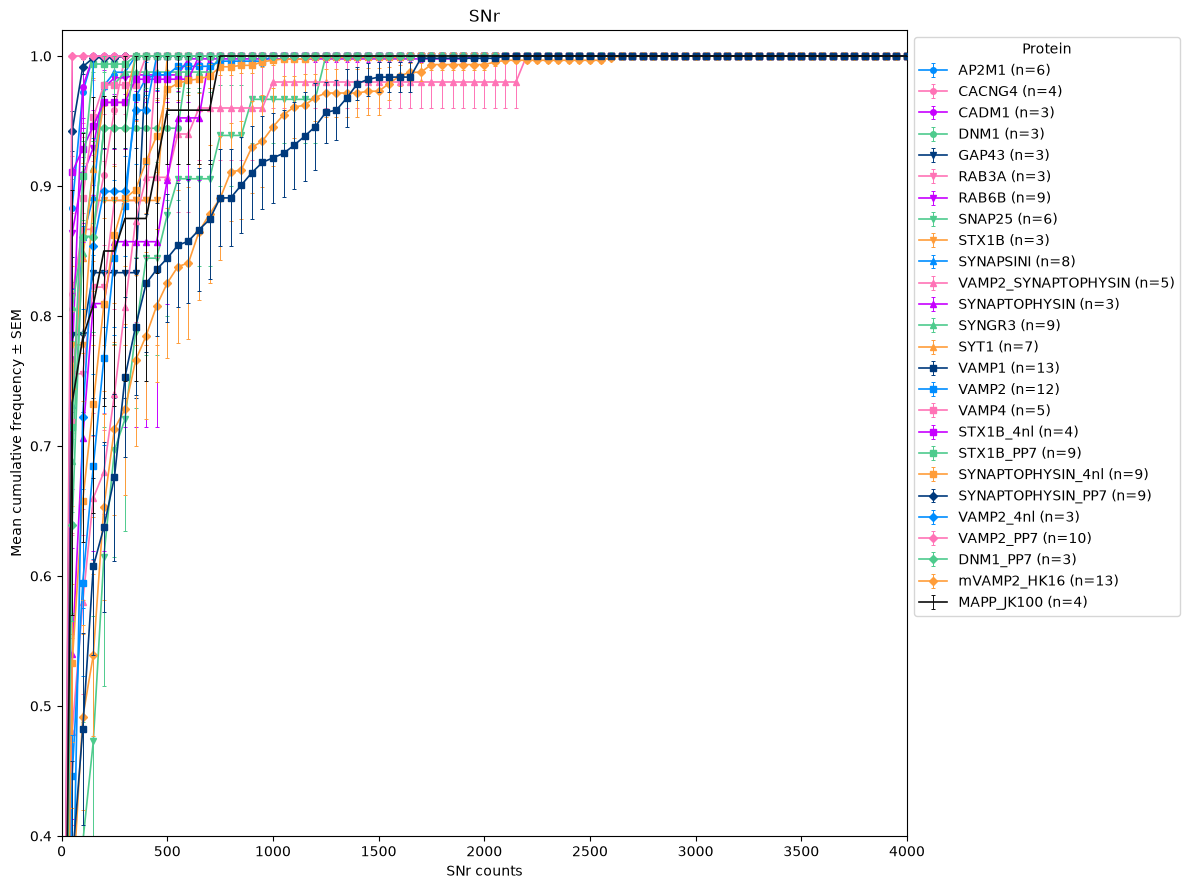

Figure saved to: E:\Data\Carrier_protein\Mouse\Second_Batch_Sequencing\thresholds\11012026_analysis\SNr_sample_mean_SEM.eps
Summary saved to: E:\Data\Carrier_protein\Mouse\Second_Batch_Sequencing\thresholds\11012026_analysis\SNr_sample_mean_SEM_summary.csv
Individual curves saved to: E:\Data\Carrier_protein\Mouse\Second_Batch_Sequencing\thresholds\11012026_analysis\SNr_sample_mean_SEM_individual_sample_curves.csv


In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import math



input_file = (
    r"E:\Data\Carrier_protein\Mouse\Second_Batch_Sequencing\thresholds\11012026_analysis\barcodes_by_sample_protein_region.csv"
)

output_file = (
    r"E:\Data\Carrier_protein\Mouse\Second_Batch_Sequencing\thresholds\11012026_analysis\SNr_sample_mean_SEM.eps"
)

region_of_interest = "SNr"
bin_width = 50

# SEM: sample 
# SD: sample 
error_type = "SEM"

# at least 2 samples
minimum_samples = 2

# at least 5 barcodes
minimum_barcodes_per_group = 3



# bin_width = 50，errorbar_every = 2 

errorbar_every = 1

# protein order

protein_list = [
    "AP2B1",
    "AP2M1",
    "CACNG4",
    "CADM1",
    "DNM1",
    "ERC2",
    "GAP43",
    "PTPRA",
    "RAB3A",
    "RAB6B",
    "SNAP25",
    "STX1B",
    "STX6",
    "SYNAPSINI",
    "VAMP2_SYNAPTOPHYSIN",
    "SYNAPTOPHYSIN",
    "SYNGR3",
    "SYT1",
    "VAMP1",
    "VAMP2",
    "VAMP4",
    "STX1B_4nl",
    "STX1B_PP7",
    "SYNAPTOPHYSIN_4nl",
    "SYNAPTOPHYSIN_PP7",
    "VAMP2_4nl",
    "VAMP2_PP7",
    "DNM1_4nl",
    "DNM1_PP7",
    "mVAMP2_HK16",
    "MAPP_JK100"
]

# color

color = [
    "#003a7d", "#008dff", "#ff73b6", "#c701ff", "#4ecb8d", "#ff9d3a",
    "#003a7d", "#008dff", "#ff73b6", "#c701ff", "#4ecb8d", "#ff9d3a",
    "#003a7d", "#008dff", "#ff73b6", "#c701ff", "#4ecb8d", "#ff9d3a",
    "#003a7d", "#008dff", "#ff73b6", "#c701ff", "#4ecb8d", "#ff9d3a",
    "#003a7d", "#008dff", "#ff73b6", "#c701ff", "#4ecb8d", "#ff9d3a",
    "#0d0d0d"
]

marker = [
    "o", "o", "o", "o", "o", "o",
    "v", "v", "v", "v", "v", "v",
    "^", "^", "^", "^", "^", "^",
    "s", "s", "s", "s", "s", "s",
    "D", "D", "D", "D", "D", "D",
    "none"
]


df = pd.read_csv(input_file)

df.columns = df.columns.str.strip()

required_cols = [
    "Sample",
    "Protein",
    "Region",
    "Region_count"
]

missing_cols = [
    col for col in required_cols
    if col not in df.columns
]

if missing_cols:
    raise ValueError(
        f"Missing required columns: {missing_cols}\n"
        f"Available columns: {df.columns.tolist()}"
    )

df["Sample"] = df["Sample"].astype(str).str.strip()
df["Protein"] = df["Protein"].astype(str).str.strip()
df["Region"] = df["Region"].astype(str).str.strip()

df["Region_count"] = pd.to_numeric(
    df["Region_count"],
    errors="coerce"
)

df = df.dropna(
    subset=[
        "Sample",
        "Protein",
        "Region",
        "Region_count"
    ]
).copy()


df["Barcode_number_in_group"] = (
    df.groupby(
        ["Sample", "Protein", "Region"]
    )["Protein"]
    .transform("size")
)

barcode_group_summary = (
    df.groupby(
        ["Sample", "Protein", "Region"],
        as_index=False
    )
    .size()
    .rename(columns={"size": "Barcode_number"})
)

barcode_group_summary["Pass_filter"] = (
    barcode_group_summary["Barcode_number"]
    >= minimum_barcodes_per_group
)


total_groups_before = len(barcode_group_summary)

groups_removed = (
    barcode_group_summary["Barcode_number"]
    < minimum_barcodes_per_group
).sum()

groups_retained = (
    barcode_group_summary["Barcode_number"]
    >= minimum_barcodes_per_group
).sum()

rows_before_filtering = len(df)

df_filtered = df[
    df["Barcode_number_in_group"]
    >= minimum_barcodes_per_group
].copy()

rows_after_filtering = len(df_filtered)

print("\nBarcode group filtering:")
print(
    f"Minimum barcodes per Sample × Protein × Region: "
    f"{minimum_barcodes_per_group}"
)
print(f"Groups before filtering: {total_groups_before}")
print(f"Groups retained: {groups_retained}")
print(f"Groups removed: {groups_removed}")
print(f"Barcode rows before filtering: {rows_before_filtering}")
print(f"Barcode rows after filtering: {rows_after_filtering}")


removed_group_summary = barcode_group_summary[
    barcode_group_summary["Barcode_number"]
    < minimum_barcodes_per_group
].copy()

if not removed_group_summary.empty:
    print("\nRemoved groups:")
    print(
        removed_group_summary[
            [
                "Sample",
                "Protein",
                "Region",
                "Barcode_number"
            ]
        ].to_string(index=False)
    )


region_df = df_filtered[
    df_filtered["Region"].str.lower()
    == region_of_interest.lower()
].copy()

region_df = region_df[
    region_df["Region_count"] > 0
].copy()

if region_df.empty:
    raise ValueError(
        f"No data remained for {region_of_interest} after applying:\n"
        f"1. At least {minimum_barcodes_per_group} barcodes per "
        f"Sample × Protein × Region\n"
        f"2. Region_count > 0"
    )


maximum_count = region_df["Region_count"].max()

maximum_bin = max(
    5000,
    math.ceil(maximum_count / bin_width) * bin_width
)

bins = np.arange(
    0,
    maximum_bin + bin_width,
    bin_width
)

print(f"Region: {region_of_interest}")
print(f"Bin width: {bin_width}")
print(f"Maximum Region_count: {maximum_count}")
print(f"Maximum bin edge: {maximum_bin}")
print(f"Samples: {sorted(region_df['Sample'].unique())}")


def calculate_cumulative_curve(counts, bins):
    """
    Calculate a cumulative probability curve for one
    Sample × Protein combination.

    Returns an array with the same length as bins.
    """

    counts = np.asarray(counts, dtype=float)

    bin_counts, _ = np.histogram(
        counts,
        bins=bins
    )

    bin_probability = bin_counts / len(counts)

    cumulative_probability = np.cumsum(
        bin_probability
    )

    # Add cumulative probability = 0 at x = 0
    cumulative_probability = np.insert(
        cumulative_probability,
        0,
        0
    )

    return cumulative_probability


plt.figure(figsize=(12, 9))

summary_records = []
curve_records = []

for j, protein in enumerate(protein_list):

    protein_df = region_df[
        region_df["Protein"] == protein
    ].copy()

    if protein_df.empty:
        print(f"No {region_of_interest} data for: {protein}")
        continue

    sample_curves = []
    included_samples = []


    for sample_name, sample_df in protein_df.groupby("Sample"):

        protein_counts = sample_df["Region_count"].to_numpy()

        if len(protein_counts) == 0:
            continue

        cumulative_curve = calculate_cumulative_curve(
            protein_counts,
            bins
        )

        sample_curves.append(cumulative_curve)
        included_samples.append(sample_name)

        for x_value, cumulative_value in zip(
            bins,
            cumulative_curve
        ):
            curve_records.append({
                "Protein": protein,
                "Sample": sample_name,
                "RA_count": x_value,
                "Cumulative_probability": cumulative_value,
                "Barcode_number": len(protein_counts)
            })

    n_samples = len(sample_curves)

    if n_samples < minimum_samples:
        print(
            f"Skipping {protein}: only {n_samples} sample(s)"
        )
        continue

    sample_curves = np.vstack(sample_curves)

   

    mean_curve = np.mean(
        sample_curves,
        axis=0
    )


    if n_samples > 1:

        sd_curve = np.std(
            sample_curves,
            axis=0,
            ddof=1
        )

        sem_curve = sd_curve / np.sqrt(n_samples)

    else:
        sd_curve = np.zeros_like(mean_curve)
        sem_curve = np.zeros_like(mean_curve)

    if error_type.upper() == "SEM":
        error_curve = sem_curve
        error_label = "SEM"

    elif error_type.upper() == "SD":
        error_curve = sd_curve
        error_label = "SD"

    else:
        raise ValueError(
            "error_type must be either 'SEM' or 'SD'."
        )

    print(
        f"{protein}: n = {n_samples} samples; "
        f"samples = {included_samples}"
    )


    for i, x_value in enumerate(bins):
        summary_records.append({
            "Protein": protein,
            "RA_count": x_value,
            "Mean_cumulative_probability": mean_curve[i],
            "SD": sd_curve[i],
            "SEM": sem_curve[i],
            "N_samples": n_samples
        })


    protein_marker = marker[j]

    marker_value = None if protein_marker == "none" else protein_marker

    front_errorbar_proteins = {
        "VAMP1",
        "MAPP_JK100"
    }

    is_front = protein in front_errorbar_proteins

    line_zorder = 99 if is_front else 2
    error_zorder = 100 if is_front else 2

    errorbar_container = plt.errorbar(
        bins,
        mean_curve,
        yerr=error_curve,
        color=color[j],
        markeredgecolor=color[j],
        markerfacecolor=color[j],
        marker=marker_value,
        markersize=4,
        linewidth=1.2,
        elinewidth=0.7,
        capsize=1.5,
        capthick=0.7,
        errorevery=errorbar_every,
        label=f"{protein} (n={n_samples})",
        zorder=line_zorder
    )

    data_line, cap_lines, barline_collections = errorbar_container.lines

    if data_line is not None:
        data_line.set_zorder(line_zorder)

    for cap_line in cap_lines:
        cap_line.set_zorder(error_zorder)

    for barline_collection in barline_collections:
        barline_collection.set_zorder(error_zorder)


plt.legend(
    loc="upper left",
    bbox_to_anchor=(1, 1),
    title="Protein"
)

plt.ylabel(
    f"Mean cumulative frequency ± {error_label}"
)

plt.xlabel(f"{region_of_interest} counts")
plt.title(region_of_interest)

plt.ylim(0.4, 1.02)
#plt.xlim(0, maximum_bin)
plt.xlim(0, 4000)
plt.tight_layout()


output_directory = os.path.dirname(output_file)

if output_directory:
    os.makedirs(
        output_directory,
        exist_ok=True
    )

plt.savefig(
    output_file,
    format="eps",
    bbox_inches="tight"
)

summary_df = pd.DataFrame(summary_records)

summary_output_file = os.path.splitext(
    output_file
)[0] + "_summary.csv"

summary_df.to_csv(
    summary_output_file,
    index=False
)

curve_df = pd.DataFrame(curve_records)

curve_output_file = os.path.splitext(
    output_file
)[0] + "_individual_sample_curves.csv"

curve_df.to_csv(
    curve_output_file,
    index=False
)

plt.show()

print(f"Figure saved to: {output_file}")
print(f"Summary saved to: {summary_output_file}")
print(f"Individual curves saved to: {curve_output_file}")

### Bird


Barcode group filtering:
Minimum barcodes per Sample × Protein × Region: 3
Groups before filtering: 479
Groups retained: 288
Groups removed: 191
Barcode rows before filtering: 6049
Barcode rows after filtering: 5785

Removed groups:
  Sample             Protein Region  Barcode_number
 sample1               AP2B1      X               2
 sample1              CACNG4     RA               2
 sample1               CADM1     RA               1
 sample1                ERC2     RA               1
 sample1               PTPRA      X               1
 sample1           STX1B_4nl     RA               2
 sample1           STX1B_4nl      X               1
 sample1           SYNAPSINI     RA               2
 sample1           SYNAPSINI      X               1
 sample1       SYNAPTOPHYSIN      X               1
 sample1   SYNAPTOPHYSIN_PP7     RA               1
sample10               AP2B1     RA               1
sample10               AP2M1     RA               1
sample10               CADM1     RA   

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


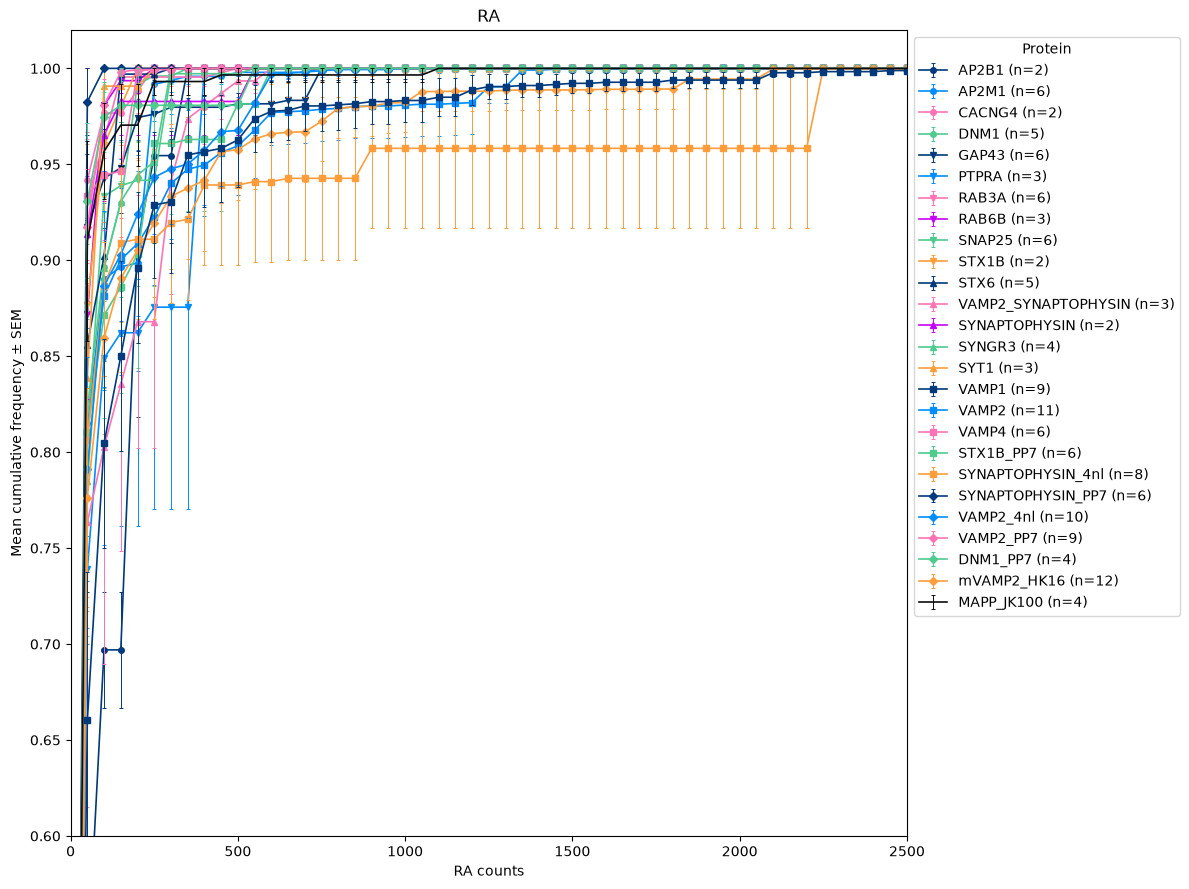

Figure saved to: D:\Data\Carrier_protein\Bird\Thresholds\11012026_analysis\RA_sample_mean_SEM.eps
Summary saved to: D:\Data\Carrier_protein\Bird\Thresholds\11012026_analysis\RA_sample_mean_SEM_summary.csv
Individual curves saved to: D:\Data\Carrier_protein\Bird\Thresholds\11012026_analysis\RA_sample_mean_SEM_individual_sample_curves.csv


In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import math



input_file = (
    r"D:\Data\Carrier_protein\Bird\Thresholds\11012026_analysis\barcodes_by_sample_protein_RA_X.csv"
)

output_file = (
    r"D:\Data\Carrier_protein\Bird\Thresholds\11012026_analysis\RA_sample_mean_SEM.eps"
)

region_of_interest = "RA"
bin_width = 50

# SEM: sample 
# SD: sample 
error_type = "SEM"

# at least 2 samples
minimum_samples = 2

# at least 5 barcodes
minimum_barcodes_per_group = 3



# bin_width = 50，errorbar_every = 2 

errorbar_every = 1

# protein order

protein_list = [
    "AP2B1",
    "AP2M1",
    "CACNG4",
    "CADM1",
    "DNM1",
    "ERC2",
    "GAP43",
    "PTPRA",
    "RAB3A",
    "RAB6B",
    "SNAP25",
    "STX1B",
    "STX6",
    "SYNAPSINI",
    "VAMP2_SYNAPTOPHYSIN",
    "SYNAPTOPHYSIN",
    "SYNGR3",
    "SYT1",
    "VAMP1",
    "VAMP2",
    "VAMP4",
    "STX1B_4nl",
    "STX1B_PP7",
    "SYNAPTOPHYSIN_4nl",
    "SYNAPTOPHYSIN_PP7",
    "VAMP2_4nl",
    "VAMP2_PP7",
    "DNM1_4nl",
    "DNM1_PP7",
    "mVAMP2_HK16",
    "MAPP_JK100"
]

# color

color = [
    "#003a7d", "#008dff", "#ff73b6", "#c701ff", "#4ecb8d", "#ff9d3a",
    "#003a7d", "#008dff", "#ff73b6", "#c701ff", "#4ecb8d", "#ff9d3a",
    "#003a7d", "#008dff", "#ff73b6", "#c701ff", "#4ecb8d", "#ff9d3a",
    "#003a7d", "#008dff", "#ff73b6", "#c701ff", "#4ecb8d", "#ff9d3a",
    "#003a7d", "#008dff", "#ff73b6", "#c701ff", "#4ecb8d", "#ff9d3a",
    "#0d0d0d"
]

marker = [
    "o", "o", "o", "o", "o", "o",
    "v", "v", "v", "v", "v", "v",
    "^", "^", "^", "^", "^", "^",
    "s", "s", "s", "s", "s", "s",
    "D", "D", "D", "D", "D", "D",
    "none"
]


df = pd.read_csv(input_file)

df.columns = df.columns.str.strip()

required_cols = [
    "Sample",
    "Protein",
    "Region",
    "Region_count"
]

missing_cols = [
    col for col in required_cols
    if col not in df.columns
]

if missing_cols:
    raise ValueError(
        f"Missing required columns: {missing_cols}\n"
        f"Available columns: {df.columns.tolist()}"
    )

df["Sample"] = df["Sample"].astype(str).str.strip()
df["Protein"] = df["Protein"].astype(str).str.strip()
df["Region"] = df["Region"].astype(str).str.strip()

df["Region_count"] = pd.to_numeric(
    df["Region_count"],
    errors="coerce"
)

df = df.dropna(
    subset=[
        "Sample",
        "Protein",
        "Region",
        "Region_count"
    ]
).copy()


df["Barcode_number_in_group"] = (
    df.groupby(
        ["Sample", "Protein", "Region"]
    )["Protein"]
    .transform("size")
)

barcode_group_summary = (
    df.groupby(
        ["Sample", "Protein", "Region"],
        as_index=False
    )
    .size()
    .rename(columns={"size": "Barcode_number"})
)

barcode_group_summary["Pass_filter"] = (
    barcode_group_summary["Barcode_number"]
    >= minimum_barcodes_per_group
)


total_groups_before = len(barcode_group_summary)

groups_removed = (
    barcode_group_summary["Barcode_number"]
    < minimum_barcodes_per_group
).sum()

groups_retained = (
    barcode_group_summary["Barcode_number"]
    >= minimum_barcodes_per_group
).sum()

rows_before_filtering = len(df)

df_filtered = df[
    df["Barcode_number_in_group"]
    >= minimum_barcodes_per_group
].copy()

rows_after_filtering = len(df_filtered)

print("\nBarcode group filtering:")
print(
    f"Minimum barcodes per Sample × Protein × Region: "
    f"{minimum_barcodes_per_group}"
)
print(f"Groups before filtering: {total_groups_before}")
print(f"Groups retained: {groups_retained}")
print(f"Groups removed: {groups_removed}")
print(f"Barcode rows before filtering: {rows_before_filtering}")
print(f"Barcode rows after filtering: {rows_after_filtering}")


removed_group_summary = barcode_group_summary[
    barcode_group_summary["Barcode_number"]
    < minimum_barcodes_per_group
].copy()

if not removed_group_summary.empty:
    print("\nRemoved groups:")
    print(
        removed_group_summary[
            [
                "Sample",
                "Protein",
                "Region",
                "Barcode_number"
            ]
        ].to_string(index=False)
    )


region_df = df_filtered[
    df_filtered["Region"].str.lower()
    == region_of_interest.lower()
].copy()

region_df = region_df[
    region_df["Region_count"] > 0
].copy()

if region_df.empty:
    raise ValueError(
        f"No data remained for {region_of_interest} after applying:\n"
        f"1. At least {minimum_barcodes_per_group} barcodes per "
        f"Sample × Protein × Region\n"
        f"2. Region_count > 0"
    )


maximum_count = region_df["Region_count"].max()

maximum_bin = max(
    5000,
    math.ceil(maximum_count / bin_width) * bin_width
)

bins = np.arange(
    0,
    maximum_bin + bin_width,
    bin_width
)

print(f"Region: {region_of_interest}")
print(f"Bin width: {bin_width}")
print(f"Maximum Region_count: {maximum_count}")
print(f"Maximum bin edge: {maximum_bin}")
print(f"Samples: {sorted(region_df['Sample'].unique())}")


def calculate_cumulative_curve(counts, bins):
    """
    Calculate a cumulative probability curve for one
    Sample × Protein combination.

    Returns an array with the same length as bins.
    """

    counts = np.asarray(counts, dtype=float)

    bin_counts, _ = np.histogram(
        counts,
        bins=bins
    )

    bin_probability = bin_counts / len(counts)

    cumulative_probability = np.cumsum(
        bin_probability
    )

    # Add cumulative probability = 0 at x = 0
    cumulative_probability = np.insert(
        cumulative_probability,
        0,
        0
    )

    return cumulative_probability


plt.figure(figsize=(12, 9))

summary_records = []
curve_records = []

for j, protein in enumerate(protein_list):

    protein_df = region_df[
        region_df["Protein"] == protein
    ].copy()

    if protein_df.empty:
        print(f"No {region_of_interest} data for: {protein}")
        continue

    sample_curves = []
    included_samples = []


    for sample_name, sample_df in protein_df.groupby("Sample"):

        protein_counts = sample_df["Region_count"].to_numpy()

        if len(protein_counts) == 0:
            continue

        cumulative_curve = calculate_cumulative_curve(
            protein_counts,
            bins
        )

        sample_curves.append(cumulative_curve)
        included_samples.append(sample_name)

        for x_value, cumulative_value in zip(
            bins,
            cumulative_curve
        ):
            curve_records.append({
                "Protein": protein,
                "Sample": sample_name,
                "RA_count": x_value,
                "Cumulative_probability": cumulative_value,
                "Barcode_number": len(protein_counts)
            })

    n_samples = len(sample_curves)

    if n_samples < minimum_samples:
        print(
            f"Skipping {protein}: only {n_samples} sample(s)"
        )
        continue

    sample_curves = np.vstack(sample_curves)

   

    mean_curve = np.mean(
        sample_curves,
        axis=0
    )


    if n_samples > 1:

        sd_curve = np.std(
            sample_curves,
            axis=0,
            ddof=1
        )

        sem_curve = sd_curve / np.sqrt(n_samples)

    else:
        sd_curve = np.zeros_like(mean_curve)
        sem_curve = np.zeros_like(mean_curve)

    if error_type.upper() == "SEM":
        error_curve = sem_curve
        error_label = "SEM"

    elif error_type.upper() == "SD":
        error_curve = sd_curve
        error_label = "SD"

    else:
        raise ValueError(
            "error_type must be either 'SEM' or 'SD'."
        )

    print(
        f"{protein}: n = {n_samples} samples; "
        f"samples = {included_samples}"
    )


    for i, x_value in enumerate(bins):
        summary_records.append({
            "Protein": protein,
            "RA_count": x_value,
            "Mean_cumulative_probability": mean_curve[i],
            "SD": sd_curve[i],
            "SEM": sem_curve[i],
            "N_samples": n_samples
        })


    protein_marker = marker[j]

    marker_value = None if protein_marker == "none" else protein_marker

    front_errorbar_proteins = {
        "VAMP1",
        "MAPP_JK100"
    }

    is_front = protein in front_errorbar_proteins

    line_zorder = 99 if is_front else 2
    error_zorder = 100 if is_front else 2

    errorbar_container = plt.errorbar(
        bins,
        mean_curve,
        yerr=error_curve,
        color=color[j],
        markeredgecolor=color[j],
        markerfacecolor=color[j],
        marker=marker_value,
        markersize=4,
        linewidth=1.2,
        elinewidth=0.7,
        capsize=1.5,
        capthick=0.7,
        errorevery=errorbar_every,
        label=f"{protein} (n={n_samples})",
        zorder=line_zorder
    )

    data_line, cap_lines, barline_collections = errorbar_container.lines

    if data_line is not None:
        data_line.set_zorder(line_zorder)

    for cap_line in cap_lines:
        cap_line.set_zorder(error_zorder)

    for barline_collection in barline_collections:
        barline_collection.set_zorder(error_zorder)


plt.legend(
    loc="upper left",
    bbox_to_anchor=(1, 1),
    title="Protein"
)

plt.ylabel(
    f"Mean cumulative frequency ± {error_label}"
)

plt.xlabel(f"{region_of_interest} counts")
plt.title(region_of_interest)

plt.ylim(0.6, 1.02)
#plt.xlim(0, maximum_bin)
plt.xlim(0, 2500)
plt.tight_layout()


output_directory = os.path.dirname(output_file)

if output_directory:
    os.makedirs(
        output_directory,
        exist_ok=True
    )

plt.savefig(
    output_file,
    format="eps",
    bbox_inches="tight"
)

summary_df = pd.DataFrame(summary_records)

summary_output_file = os.path.splitext(
    output_file
)[0] + "_summary.csv"

summary_df.to_csv(
    summary_output_file,
    index=False
)

curve_df = pd.DataFrame(curve_records)

curve_output_file = os.path.splitext(
    output_file
)[0] + "_individual_sample_curves.csv"

curve_df.to_csv(
    curve_output_file,
    index=False
)

plt.show()

print(f"Figure saved to: {output_file}")
print(f"Summary saved to: {summary_output_file}")
print(f"Individual curves saved to: {curve_output_file}")

### Calculate rank

In [11]:
import pandas as pd
import numpy as np

# Mouse
#df = pd.read_csv(r"E:\Data\Carrier_protein\Mouse\Second_Batch_Sequencing\thresholds\11012026_analysis\Mouse_mean_Region_count_All_protein.csv")

# Bird
df = pd.read_csv(r"D:\Data\Carrier_protein\Bird\Thresholds\11012026_analysis\Bird_mean_Region_count_All_protein.csv")

protein_cols = [col for col in df.columns if col not in ['Sample', 'Region']]

df[protein_cols] = df[protein_cols].apply(pd.to_numeric, errors='coerce')

n_proteins = len(protein_cols)

print('Number of proteins:', n_proteins)


rank_matrix = df[protein_cols].rank(
    axis=1,
    ascending=False,
    method='min',
    na_option='keep'
)


rank_matrix = df[protein_cols].rank(
    axis=1,
    ascending=False,
    method='min',
    na_option='keep'
)

rank_matrix = rank_matrix.astype('Int64')


result = pd.concat(
    [
        df[['Sample', 'Region']],
        rank_matrix
    ],
    axis=1
)

# Mouse
#result.to_csv(r'E:\Data\Carrier_protein\Mouse\Second_Batch_Sequencing\thresholds\11012026_analysis\Mouse_protein_rank_matrix_NOT_GT5.csv', index=False)
# Bird
result.to_csv(r'D:\Data\Carrier_protein\Bird\Thresholds\11012026_analysis\Mouse_protein_rank_matrix_NOT_GT5.csv', index=False)

print(result)

Number of proteins: 31
      Sample Region  AP2B1  AP2M1  CACNG4  CADM1  DNM1  ERC2  GAP43  PTPRA  \
0    sample1     RA      7     13      15      5    11     3     17     20   
1    sample1      X     22      9    <NA>     28    13  <NA>     19     26   
2   sample10     RA      7      2    <NA>     10    12  <NA>      4   <NA>   
3   sample10      X   <NA>   <NA>    <NA>   <NA>  <NA>  <NA>     11   <NA>   
4   sample11     RA   <NA>   <NA>    <NA>   <NA>  <NA>  <NA>   <NA>   <NA>   
5   sample11      X   <NA>     18      15   <NA>     8  <NA>     14   <NA>   
6   sample12     RA   <NA>      8       3   <NA>  <NA>  <NA>   <NA>   <NA>   
7   sample12      X   <NA>   <NA>    <NA>   <NA>  <NA>  <NA>   <NA>   <NA>   
8    sample2     RA   <NA>     12    <NA>   <NA>  <NA>  <NA>   <NA>   <NA>   
9    sample2      X   <NA>     14    <NA>   <NA>  <NA>  <NA>   <NA>   <NA>   
10   sample3     RA      6      9      20     27    14    23     13     10   
11   sample3      X     17     10      16

### Rank heatmap

Regions found:
RA
X

Processing: RA

Protein order:
1 mVAMP2_HK16 Rank sum = 338.0
2 VAMP2 Rank sum = 332.0
3 VAMP1 Rank sum = 324.0
4 VAMP2_4nl Rank sum = 290.0
5 SYNAPTOPHYSIN_4nl Rank sum = 269.0
6 STX1B_PP7 Rank sum = 239.0
7 VAMP2_PP7 Rank sum = 235.0
8 AP2M1 Rank sum = 198.0
9 VAMP4 Rank sum = 190.0
10 RAB3A Rank sum = 180.0
11 VAMP2_SYNAPTOPHYSIN Rank sum = 173.0
12 SYNGR3 Rank sum = 173.0
13 SNAP25 Rank sum = 170.0
14 MAPP_JK100 Rank sum = 167.0
15 GAP43 Rank sum = 144.0
16 STX6 Rank sum = 136.0
17 DNM1 Rank sum = 132.0
18 SYT1 Rank sum = 131.0
19 CACNG4 Rank sum = 127.0
20 SYNAPTOPHYSIN_PP7 Rank sum = 122.0
21 SYNAPTOPHYSIN Rank sum = 121.0
22 AP2B1 Rank sum = 120.0
23 DNM1_PP7 Rank sum = 104.0
24 RAB6B Rank sum = 96.0
25 PTPRA Rank sum = 94.0
26 CADM1 Rank sum = 77.0
27 ERC2 Rank sum = 63.0
28 STX1B_4nl Rank sum = 59.0
29 STX1B Rank sum = 55.0
30 SYNAPSINI Rank sum = 55.0
31 DNM1_4nl Rank sum = 34.0


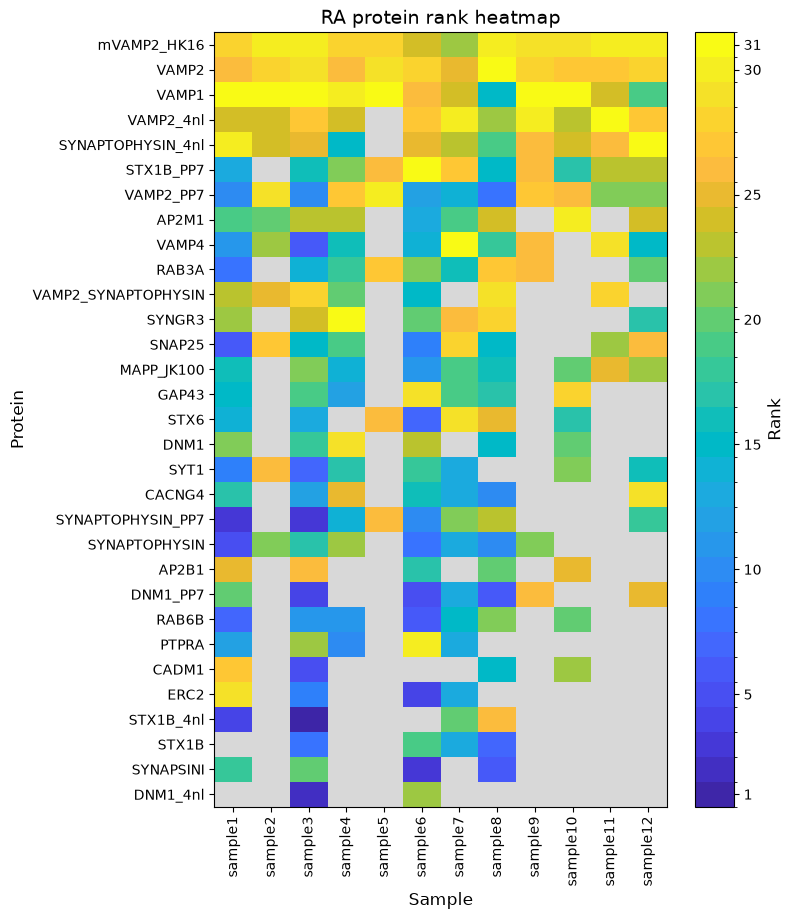

Saved:
RA_protein_rank_heatmap.png
RA_protein_rank_heatmap.pdf
RA_ordered_rank_matrix.csv

Processing: X

Protein order:
1 mVAMP2_HK16 Rank sum = 340.0
2 VAMP2 Rank sum = 326.0
3 VAMP2_4nl Rank sum = 320.0
4 VAMP1 Rank sum = 281.0
5 SYNAPTOPHYSIN_4nl Rank sum = 241.0
6 SYNAPTOPHYSIN_PP7 Rank sum = 225.0
7 STX1B_PP7 Rank sum = 219.0
8 VAMP2_PP7 Rank sum = 219.0
9 SNAP25 Rank sum = 202.0
10 VAMP2_SYNAPTOPHYSIN Rank sum = 200.0
11 RAB3A Rank sum = 194.0
12 MAPP_JK100 Rank sum = 193.0
13 STX6 Rank sum = 172.0
14 GAP43 Rank sum = 172.0
15 RAB6B Rank sum = 151.0
16 SYNGR3 Rank sum = 150.0
17 AP2M1 Rank sum = 147.0
18 CACNG4 Rank sum = 133.0
19 DNM1_PP7 Rank sum = 131.0
20 VAMP4 Rank sum = 130.0
21 SYT1 Rank sum = 118.0
22 SYNAPTOPHYSIN Rank sum = 117.0
23 STX1B Rank sum = 102.0
24 AP2B1 Rank sum = 81.0
25 SYNAPSINI Rank sum = 78.0
26 STX1B_4nl Rank sum = 78.0
27 DNM1 Rank sum = 73.0
28 ERC2 Rank sum = 51.0
29 PTPRA Rank sum = 50.0
30 CADM1 Rank sum = 48.0
31 DNM1_4nl Rank sum = 31.0


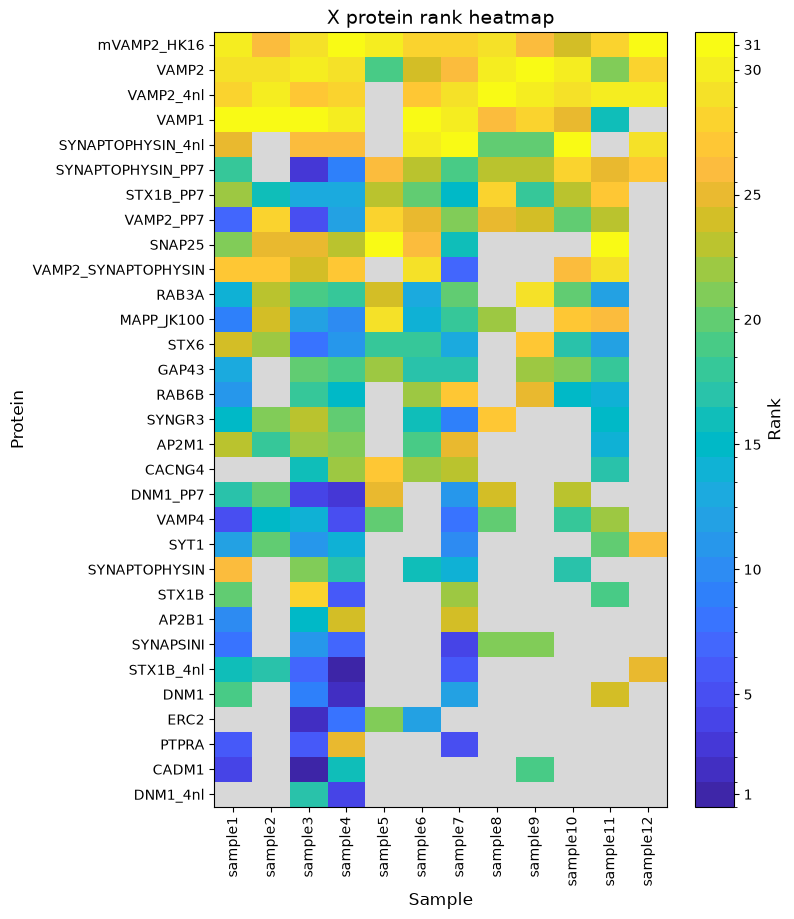

Saved:
X_protein_rank_heatmap.png
X_protein_rank_heatmap.pdf
X_ordered_rank_matrix.csv


In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from matplotlib.colors import ListedColormap, BoundaryNorm


colors31 = np.array([

    [0.9765, 0.9843, 0.0824],  # rank 1
    [0.9608, 0.9333, 0.1294],  # rank 2
    [0.9608, 0.8824, 0.1569],  # rank 3
    [0.9843, 0.8275, 0.1804],  # rank 4
    [0.9961, 0.7804, 0.2078],  # rank 5
    [0.9882, 0.7373, 0.2431],  # rank 6
    [0.9176, 0.7294, 0.1882],  # rank 7
    [0.8275, 0.7490, 0.1529],  # rank 8
    [0.7333, 0.7686, 0.1843],  # rank 9
    [0.6157, 0.7882, 0.2627],  # rank 10
    [0.5059, 0.8000, 0.3490],  # rank 11
    [0.3804, 0.8039, 0.4471],  # rank 12
    [0.2824, 0.7961, 0.5255],  # rank 13
    [0.2118, 0.7843, 0.6000],  # rank 14
    [0.1608, 0.7647, 0.6667],  # rank 15
    [0.0627, 0.7451, 0.7294],  # rank 16
    [0.0000, 0.7255, 0.7804],  # rank 17
    [0.0627, 0.6980, 0.8353],  # rank 18
    [0.1098, 0.6667, 0.8745],  # rank 19
    [0.1373, 0.6314, 0.8941],  # rank 20
    [0.1529, 0.5922, 0.9216],  # rank 21
    [0.1765, 0.5490, 0.9529],  # rank 22
    [0.1843, 0.5020, 0.9804],  # rank 23
    [0.2235, 0.4549, 1.0000],  # rank 24
    [0.2627, 0.4039, 0.9922],  # rank 25
    [0.2784, 0.3529, 0.9765],  # rank 26
    [0.2824, 0.3098, 0.9490],  # rank 27
    [0.2784, 0.2667, 0.9098],  # rank 28
    [0.2706, 0.2196, 0.8431],  # rank 29
    [0.2588, 0.1843, 0.7608],  # rank 30
    [0.2431, 0.1490, 0.6588],  # rank 31

])



cmap = ListedColormap(colors31)

cmap.set_bad(color=[0.85, 0.85, 0.85])

bounds = np.arange(0.5, 32.5, 1)

norm = BoundaryNorm(
    bounds,
    ncolors=cmap.N
)

# Load files
# Mouse
#df = pd.read_csv(r"E:\Data\Carrier_protein\Mouse\Second_Batch_Sequencing\thresholds\11012026_analysis\Mouse_protein_rank_matrix_NOT_GT5.csv")

# Bird
df = pd.read_csv(r"D:\Data\Carrier_protein\Bird\Thresholds\11012026_analysis\Mouse_protein_rank_matrix_NOT_GT5.csv")


protein_cols = [
    col for col in df.columns
    if col not in ['Sample', 'Region']
]

df[protein_cols] = df[protein_cols].apply(
    pd.to_numeric,
    errors='coerce'
)

df[protein_cols] = 32 - df[protein_cols]

cmap = ListedColormap(colors31[::-1])
cmap.set_bad(color=[0.85, 0.85, 0.85])

def natural_sort_key(text):

    return [
        int(x) if x.isdigit() else x.lower()
        for x in re.split(r'(\d+)', str(text))
    ]



regions = df['Region'].dropna().unique()

print('Regions found:')

for region in regions:
    print(region)


for region in regions:

    print('\nProcessing:', region)

    region_df = df[
        df['Region'] == region
    ].copy()

    sample_order = sorted(
        region_df['Sample'].astype(str).unique(),
        key=natural_sort_key
    )


    region_df['Sample'] = pd.Categorical(
        region_df['Sample'].astype(str),
        categories=sample_order,
        ordered=True
    )

    region_df = region_df.sort_values('Sample')

    heatmap_data = (
        region_df
        .set_index('Sample')[protein_cols]
        .T
    )


    score_sum = heatmap_data.fillna(1).sum(axis=1)

    protein_order = (
        score_sum
        .sort_values(ascending=False)
        .index
    )


    heatmap_data = heatmap_data.loc[
        protein_order
    ]

    print('\nProtein order:')

    for i, protein in enumerate(protein_order, start=1):

        print(
            i,
            protein,
            'Rank sum =',
            score_sum[protein]
        )

    n_samples = heatmap_data.shape[1]
    n_proteins = heatmap_data.shape[0]

    fig_width = max(
        8,
        n_samples * 0.55
    )

    fig_height = max(
        7,
        n_proteins * 0.30
    )


    fig, ax = plt.subplots(
        figsize=(fig_width, fig_height)
    )

    im = ax.imshow(
    heatmap_data.to_numpy(dtype=float),
    cmap=cmap,
    norm=norm,
    aspect='auto',
    interpolation='nearest')

    ax.set_xticks(
        np.arange(n_samples)
    )

    ax.set_xticklabels(
        heatmap_data.columns,
        rotation=90
    )


    ax.set_yticks(
        np.arange(n_proteins)
    )

    ax.set_yticklabels(
        heatmap_data.index
    )


    ax.set_xlabel(
        'Sample',
        fontsize=12
    )

    ax.set_ylabel(
        'Protein',
        fontsize=12
    )


    ax.set_title(
        f'{region} protein rank heatmap',
        fontsize=14
    )

    cbar = fig.colorbar(
        im,
        ax=ax,
        boundaries=bounds,

        ticks=[
            1,
            5,
            10,
            15,
            20,
            25,
            30,
            31
        ]
    )


    cbar.set_label(
        'Rank',
        fontsize=12
    )


    plt.tight_layout()


    png_name = (
        f'{region}_protein_rank_heatmap.png'
    )

    plt.savefig(
        png_name,
        dpi=300,
        bbox_inches='tight'
    )


    pdf_name = (
        f'{region}_protein_rank_heatmap.pdf'
    )

    plt.savefig(
        pdf_name,
        bbox_inches='tight'
    )

    EPS_name = (
            f'{region}_protein_rank_heatmap.eps'
        )
    plt.savefig(
        EPS_name,
        format='eps',
        bbox_inches='tight') 


    csv_name = (
        f'{region}_ordered_rank_matrix.csv'
    )

    heatmap_data.to_csv(
        csv_name
    )

    plt.show()


    print('Saved:')
    print(png_name)
    print(pdf_name)
    print(csv_name)

In [15]:
protein_colors = {

    "AP2B1": (0.1900, 0.0718, 0.2322),
    "AP2M1": (0.2250, 0.1635, 0.4510),
    "CACNG4": (0.2537, 0.2633, 0.6541),
    "CADM1": (0.2697, 0.3488, 0.7963),

    "DNM1": (0.2769, 0.4415, 0.9133),
    "ERC2": (0.2738, 0.5207, 0.9790),
    "GAP43": (0.2443, 0.6094, 0.9970),
    "PTPRA": (0.1933, 0.6881, 0.9619),

    "RAB3A": (0.1328, 0.7716, 0.8858),
    "RAB6B": (0.0975, 0.8371, 0.8034),
    "SNAP25": (0.1034, 0.8960, 0.7150),
    "STX1B": (0.1632, 0.9361, 0.6314),

    "STX6": (0.2760, 0.9709, 0.5165),
    "SYNAPSINI": (0.3968, 0.9910, 0.4110),
    "VAMP2_SYNAPTOPHYSIN": (0.5325, 0.9992, 0.3058),
    "SYNAPTOPHYSIN": (0.6436, 0.9900, 0.2336),

    "SYNGR3": (0.7260, 0.9647, 0.2064),
    "SYT1": (0.8141, 0.9186, 0.2055),

    "VAMP1": (0.8833, 0.8655, 0.2172),
    "VAMP2": (0.9449, 0.7963, 0.2280),
    "VAMP4": (0.9800, 0.7300, 0.2216),

    "STX1B_4nl": (0.9961, 0.6428, 0.1916),
    "STX1B_PP7": (0.9930, 0.5521, 0.1542),

    "SYNAPTOPHYSIN_4nl": (0.9723, 0.4456, 0.1080),
    "SYNAPTOPHYSIN_PP7": (0.9408, 0.3557, 0.0703),

    "VAMP2_4nl": (0.8930, 0.2698, 0.0399),
    "VAMP2_PP7": (0.8393, 0.2065, 0.0231),

    "DNM1_4nl": (0.7648, 0.1437, 0.0104),
    "DNM1_PP7": (0.6860, 0.0954, 0.0048),

    "mVAMP2_HK16": (0.5834, 0.0493, 0.0049),

    "MAPP_JK100": (0.4796, 0.0158, 0.0106)
}


Data used for plotting:
                     RA_mean_rank  X_mean_rank     RA_sem     X_sem  RA_n  \
Protein                                                                     
AP2B1                    9.400000    13.750000   1.749286  3.473111     5   
AP2M1                   10.333333    11.714286   1.563472  1.375193     9   
CACNG4                  14.571429    10.833333   2.662412  1.661659     7   
CADM1                   14.750000    22.000000   4.767512  4.415880     4   
DNM1                    11.000000    18.800000   1.949359  3.839271     6   
DNM1_4nl                20.000000    21.500000  10.000000  6.500000     2   
DNM1_PP7                17.857143    16.125000   3.608380  3.130709     7   
ERC2                    18.250000    21.250000   5.406401  3.986958     4   
GAP43                   12.142857    13.222222   2.414525  0.968644     7   
MAPP_JK100              13.777778    12.900000   1.450841  2.363848     9   
PTPRA                   14.600000    21.500000   3.

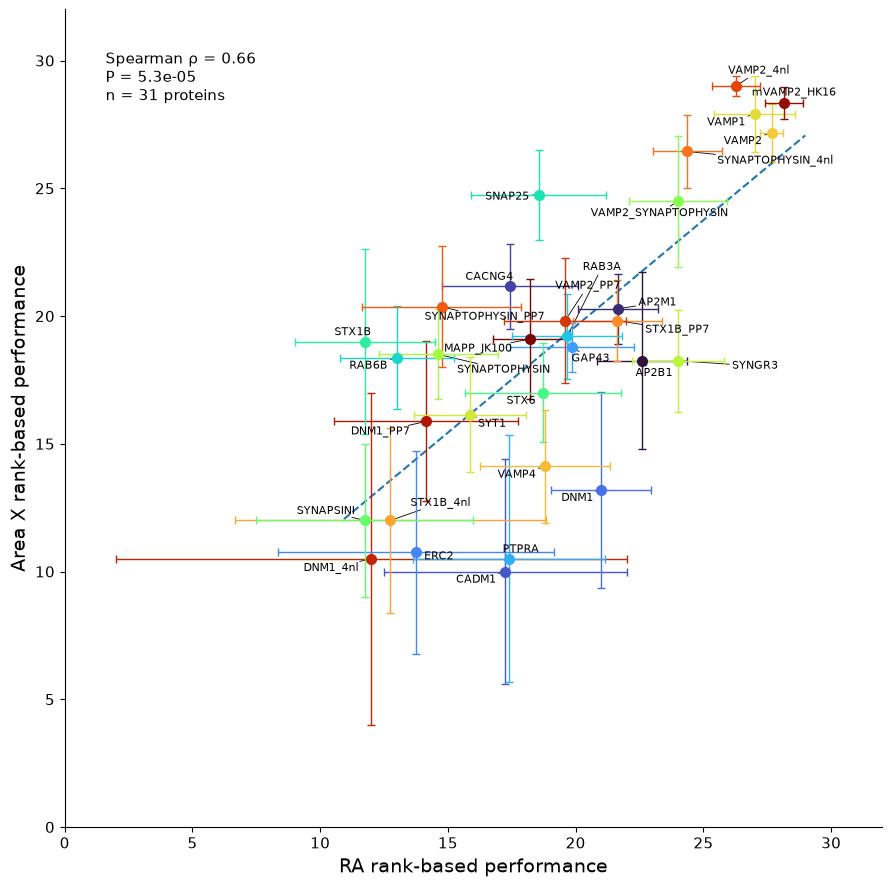


Files saved:
RA_vs_X_rank_based_performance_correlation.png
RA_vs_X_rank_based_performance_correlation.pdf
RA_vs_X_rank_based_performance_mean_SEM.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, spearmanr, linregress
from adjustText import adjust_text



df = pd.read_csv(r"D:\Data\Carrier_protein\Bird\Thresholds\11012026_analysis\Mouse_protein_rank_matrix_NOT_GT5.csv")



protein_cols = [
    col for col in df.columns
    if col not in ['Sample', 'Region']
]


df[protein_cols] = df[protein_cols].apply(
    pd.to_numeric,
    errors='coerce'
)



long_df = df.melt(
    id_vars=['Sample', 'Region'],
    value_vars=protein_cols,
    var_name='Protein',
    value_name='Value'
)



stats = (
    long_df
    .groupby(['Protein', 'Region'])['Value']
    .agg(
        mean='mean',
        sem='sem',
        n='count'
    )
    .reset_index()
)



mean_table = stats.pivot(
    index='Protein',
    columns='Region',
    values='mean'
)

sem_table = stats.pivot(
    index='Protein',
    columns='Region',
    values='sem'
)

n_table = stats.pivot(
    index='Protein',
    columns='Region',
    values='n'
)



plot_df = pd.DataFrame({

    'RA_mean_rank': mean_table.get('RA'),
    'X_mean_rank': mean_table.get('X'),

    'RA_sem': sem_table.get('RA'),
    'X_sem': sem_table.get('X'),

    'RA_n': n_table.get('RA'),
    'X_n': n_table.get('X')
})



plot_df = plot_df.dropna(
    subset=[
        'RA_mean_rank',
        'X_mean_rank'
    ]
).copy()



plot_df['RA_performance'] = (
    32 - plot_df['RA_mean_rank']
)

plot_df['X_performance'] = (
    32 - plot_df['X_mean_rank']
)



plot_df['RA_performance_sem'] = plot_df['RA_sem']
plot_df['X_performance_sem'] = plot_df['X_sem']



print('\nData used for plotting:')
print(plot_df)



pearson_r, pearson_p = pearsonr(
    plot_df['RA_performance'],
    plot_df['X_performance']
)



spearman_r, spearman_p = spearmanr(
    plot_df['RA_performance'],
    plot_df['X_performance']
)


print('\nPearson correlation')
print(f'r = {pearson_r:.4f}')
print(f'p = {pearson_p:.4g}')

print('\nSpearman correlation')
print(f'rho = {spearman_r:.4f}')
print(f'p = {spearman_p:.4g}')



reg = linregress(
    plot_df['RA_performance'],
    plot_df['X_performance']
)

print('\nLinear regression')
print(f'Slope = {reg.slope:.4f}')
print(f'Intercept = {reg.intercept:.4f}')
print(f'R² = {reg.rvalue**2:.4f}')



fig, ax = plt.subplots(
    figsize=(9, 9)
)



for protein, row in plot_df.iterrows():

    x = row['RA_performance']
    y = row['X_performance']

    xerr = row['RA_performance_sem']
    yerr = row['X_performance_sem']


    if pd.notna(xerr) and pd.notna(yerr):

        ax.errorbar(
            x,
            y,

            xerr=xerr,
            yerr=yerr,

            fmt='o',

            color=protein_color,

            ecolor=protein_color,

            markersize=7,

            capsize=3,
            capthick=1,

            elinewidth=1,

            zorder=3
        )



    else:

        xerr_plot = xerr if pd.notna(xerr) else None
        yerr_plot = yerr if pd.notna(yerr) else None

        ax.errorbar(
            x,
            y,

            xerr=xerr_plot,
            yerr=yerr_plot,

            fmt='o',

            color=protein_color,

            ecolor=protein_color,

            markersize=7,

            capsize=3,
            capthick=1,

            elinewidth=1,

            zorder=3
        )



x_min = plot_df['RA_performance'].min()
x_max = plot_df['RA_performance'].max()

x_padding = (x_max - x_min) * 0.05

x_line = np.linspace(
    x_min - x_padding,
    x_max + x_padding,
    300
)

y_line = (
    reg.slope * x_line
    + reg.intercept
)

ax.plot(
    x_line,
    y_line,
    '--',
    linewidth=1.5,
    zorder=1
)



texts = []

for protein, row in plot_df.iterrows():

    x = row['RA_performance']
    y = row['X_performance']

    text = ax.text(
        x,
        y,

        protein,

        fontsize=8,

        ha='center',
        va='center',

        zorder=4
    )

    texts.append(text)



adjust_text(

    texts,

    x=plot_df['RA_performance'].values,
    y=plot_df['X_performance'].values,

    ax=ax,

    expand=(1.4, 1.6),

    force_text=(0.8, 0.8),

    force_static=(0.5, 0.5),

    force_pull=(0.02, 0.02),

    arrowprops=dict(
        arrowstyle='-',
        lw=0.6
    )
)


# ============================================================
# 20. Axis labels
# ============================================================

ax.set_xlabel(
    'RA rank-based performance',
    fontsize=14
)

ax.set_ylabel(
    'Area X rank-based performance',
    fontsize=14
)



correlation_text = (

    f'Spearman ρ = {spearman_r:.2f}\n'
    f'P = {spearman_p:.3g}\n'
    f'n = {len(plot_df)} proteins'
)

ax.text(
    0.05,
    0.95,

    correlation_text,

    transform=ax.transAxes,

    ha='left',
    va='top',

    fontsize=11
)



all_values = np.concatenate([

    plot_df['RA_performance'].values,
    plot_df['X_performance'].values
])

all_sem = np.concatenate([

    plot_df['RA_performance_sem'].fillna(0).values,
    plot_df['X_performance_sem'].fillna(0).values
])


data_min = np.min(all_values - all_sem)
data_max = np.max(all_values + all_sem)

padding = max(
    1,
    (data_max - data_min) * 0.10
)

axis_min = max(
    0,
    data_min - padding
)

axis_max = min(
    32,
    data_max + padding
)

ax.set_xlim(
    axis_min,
    axis_max
)

ax.set_ylim(
    axis_min,
    axis_max
)

ax.set_aspect(
    'equal',
    adjustable='box'
)



ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.tick_params(
    axis='both',
    labelsize=11
)

plt.tight_layout()



plt.savefig(
    'RA_vs_X_rank_based_performance_correlation.png',
    dpi=300,
    bbox_inches='tight'
)

plt.savefig(
    'RA_vs_X_rank_based_performance_correlation.pdf',
    bbox_inches='tight'
)

plt.savefig(
        'RA_vs_X_rank_based_performance_correlation.eps',
        format='eps',
        bbox_inches='tight') 

plt.show()


'''
plot_df.to_csv(
    'RA_vs_X_rank_based_performance_mean_SEM.csv'
)
'''

print('\nFiles saved:')
print('RA_vs_X_rank_based_performance_correlation.png')
print('RA_vs_X_rank_based_performance_correlation.pdf')
print('RA_vs_X_rank_based_performance_mean_SEM.csv')


Regions found:
Medulla
SNr
Thalamus

Region pairs:
('Medulla', 'SNr')
('Medulla', 'Thalamus')
('SNr', 'Thalamus')

Medulla vs SNr

Proteins used:
                     Medulla_mean_rank  SNr_mean_rank  Medulla_performance  \
Protein                                                                      
AP2B1                        14.500000      16.666667            17.500000   
AP2M1                        15.200000      19.222222            16.800000   
CACNG4                       14.666667      16.111111            17.333333   
CADM1                        19.000000      17.181818            13.000000   
DNM1                         14.428571      17.000000            17.571429   
DNM1_4nl                     19.200000      16.666667            12.800000   
DNM1_PP7                     16.375000      14.250000            15.625000   
ERC2                         10.000000       9.000000            22.000000   
GAP43                        13.400000      15.166667            18.60000

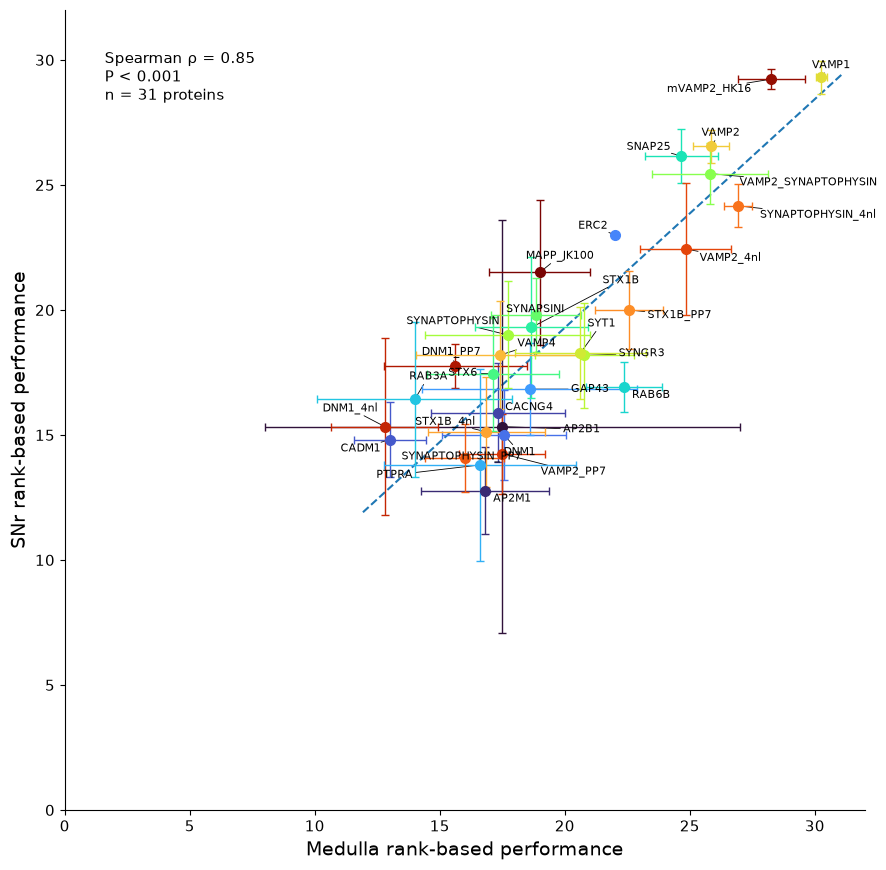


Medulla vs Thalamus

Proteins used:
                     Medulla_mean_rank  Thalamus_mean_rank  \
Protein                                                      
AP2B1                        14.500000           21.090909   
AP2M1                        15.200000           18.166667   
CACNG4                       14.666667           18.363636   
CADM1                        19.000000           22.000000   
DNM1                         14.428571           15.750000   
DNM1_4nl                     19.200000           21.000000   
DNM1_PP7                     16.375000           22.000000   
ERC2                         10.000000           21.250000   
GAP43                        13.400000           20.181818   
MAPP_JK100                   13.000000            8.500000   
PTPRA                        15.400000           18.400000   
RAB3A                        18.000000           17.166667   
RAB6B                         9.636364           16.750000   
SNAP25                        7.3

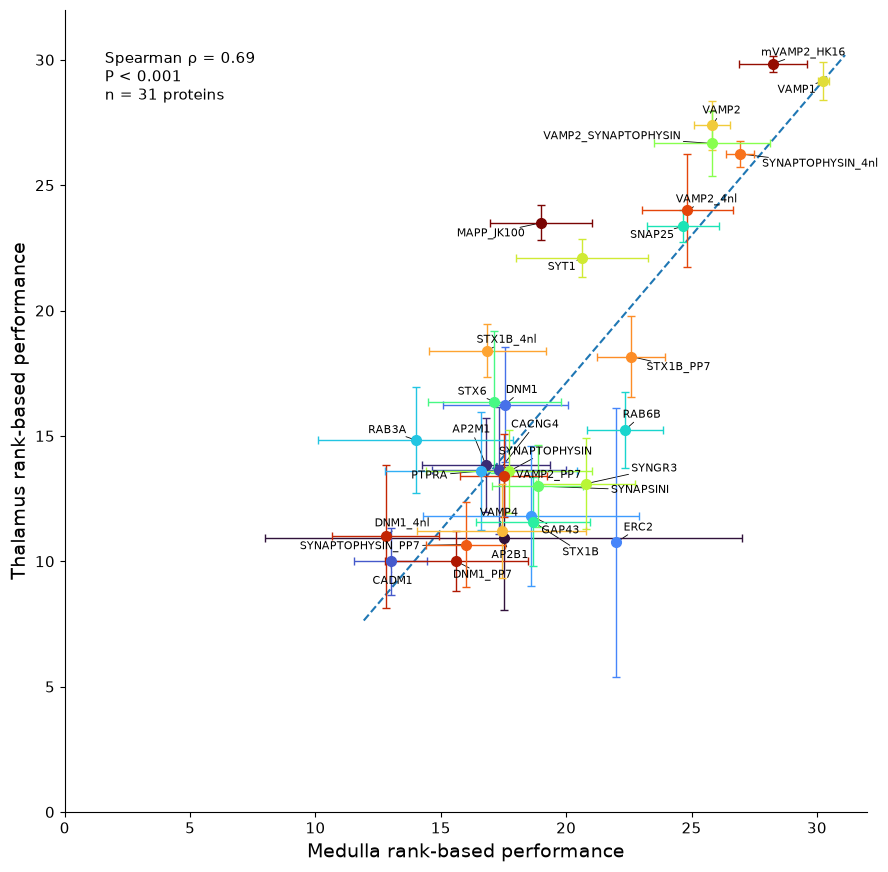


SNr vs Thalamus

Proteins used:
                     SNr_mean_rank  Thalamus_mean_rank  SNr_performance  \
Protein                                                                   
AP2B1                    16.666667           21.090909        15.333333   
AP2M1                    19.222222           18.166667        12.777778   
CACNG4                   16.111111           18.363636        15.888889   
CADM1                    17.181818           22.000000        14.818182   
DNM1                     17.000000           15.750000        15.000000   
DNM1_4nl                 16.666667           21.000000        15.333333   
DNM1_PP7                 14.250000           22.000000        17.750000   
ERC2                      9.000000           21.250000        23.000000   
GAP43                    15.166667           20.181818        16.833333   
MAPP_JK100               10.500000            8.500000        21.500000   
PTPRA                    18.200000           18.400000        13.80

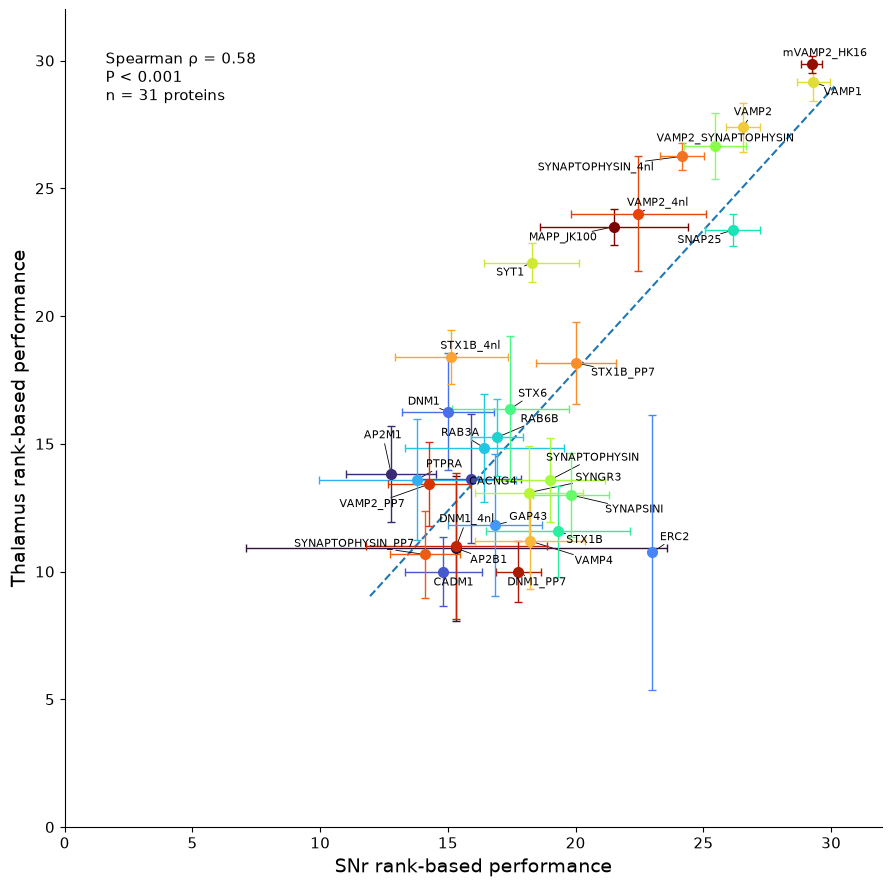


All analyses finished

Correlation summary:
  Region_X  Region_Y  N_proteins  Pearson_r     Pearson_p  Spearman_rho  \
0  Medulla       SNr          31   0.887850  2.745119e-11      0.848457   
1  Medulla  Thalamus          31   0.835258  5.088285e-09      0.692277   
2      SNr  Thalamus          31   0.803277  5.352197e-08      0.578141   

     Spearman_p  Regression_slope  Regression_intercept  Regression_R2  
0  1.657905e-09          0.914277              1.003009       0.788278  
1  1.598592e-05          1.175097             -6.379338       0.697656  
2  6.582814e-04          1.097440             -4.079323       0.645254  


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, spearmanr, linregress
from adjustText import adjust_text
from itertools import combinations



df = pd.read_csv(r"E:\Data\Carrier_protein\Mouse\Second_Batch_Sequencing\thresholds\11012026_analysis\Mouse_protein_rank_matrix_NOT_GT5.csv")



protein_cols = [
    col for col in df.columns
    if col not in ['Sample', 'Region']
]


df[protein_cols] = df[protein_cols].apply(
    pd.to_numeric,
    errors='coerce'
)


long_df = df.melt(
    id_vars=['Sample', 'Region'],
    value_vars=protein_cols,
    var_name='Protein',
    value_name='Value'
)



stats = (
    long_df
    .groupby(['Protein', 'Region'])['Value']
    .agg(
        mean_rank='mean',
        sem='sem',
        n='count'
    )
    .reset_index()
)



stats['performance'] = 32 - stats['mean_rank']

stats.to_csv(
    'Mouse_all_regions_mean_SEM_performance.csv',
    index=False
)


performance_table = stats.pivot(
    index='Protein',
    columns='Region',
    values='performance'
)

mean_rank_table = stats.pivot(
    index='Protein',
    columns='Region',
    values='mean_rank'
)

sem_table = stats.pivot(
    index='Protein',
    columns='Region',
    values='sem'
)

n_table = stats.pivot(
    index='Protein',
    columns='Region',
    values='n'
)



regions = df['Region'].dropna().unique().tolist()

print('\nRegions found:')
for region in regions:
    print(region)



region_pairs = list(combinations(regions, 2))

print('\nRegion pairs:')
for pair in region_pairs:
    print(pair)



correlation_results = []



for region_x, region_y in region_pairs:

    print('\n=======================================')
    print(f'{region_x} vs {region_y}')
    print('=======================================')



    plot_df = pd.DataFrame({

        f'{region_x}_mean_rank':
            mean_rank_table[region_x],

        f'{region_y}_mean_rank':
            mean_rank_table[region_y],

        f'{region_x}_performance':
            performance_table[region_x],

        f'{region_y}_performance':
            performance_table[region_y],

        f'{region_x}_sem':
            sem_table[region_x],

        f'{region_y}_sem':
            sem_table[region_y],

        f'{region_x}_n':
            n_table[region_x],

        f'{region_y}_n':
            n_table[region_y]

    })



    plot_df = plot_df.dropna(
        subset=[
            f'{region_x}_performance',
            f'{region_y}_performance'
        ]
    ).copy()



    print('\nProteins used:')
    print(plot_df)


    if len(plot_df) < 2:

        print(
            f'Not enough proteins for '
            f'{region_x} vs {region_y}.'
        )

        continue



    x = plot_df[
        f'{region_x}_performance'
    ].values

    y = plot_df[
        f'{region_y}_performance'
    ].values



    pearson_r, pearson_p = pearsonr(
        x,
        y
    )



    spearman_r, spearman_p = spearmanr(
        x,
        y
    )



    regression = linregress(
        x,
        y
    )

    slope = regression.slope
    intercept = regression.intercept
    r_squared = regression.rvalue ** 2


    print('\nPearson:')
    print(f'r = {pearson_r:.4f}')
    print(f'p = {pearson_p:.4g}')

    print('\nSpearman:')
    print(f'rho = {spearman_r:.4f}')
    print(f'p = {spearman_p:.4g}')

    print('\nLinear regression:')
    print(f'slope = {slope:.4f}')
    print(f'intercept = {intercept:.4f}')
    print(f'R² = {r_squared:.4f}')


    correlation_results.append({

        'Region_X': region_x,
        'Region_Y': region_y,

        'N_proteins': len(plot_df),

        'Pearson_r': pearson_r,
        'Pearson_p': pearson_p,

        'Spearman_rho': spearman_r,
        'Spearman_p': spearman_p,

        'Regression_slope': slope,
        'Regression_intercept': intercept,
        'Regression_R2': r_squared

    })



    fig, ax = plt.subplots(
        figsize=(9, 9)
    )


    for protein, row in plot_df.iterrows():

        x_value = row[
            f'{region_x}_performance'
        ]

        y_value = row[
            f'{region_y}_performance'
        ]

        x_sem = row[
            f'{region_x}_sem'
        ]

        y_sem = row[
            f'{region_y}_sem'
        ]

        xerr_plot = (
            x_sem
            if pd.notna(x_sem)
            else None
        )

        yerr_plot = (
            y_sem
            if pd.notna(y_sem)
            else None
        )


        protein_color = protein_colors.get(
            protein,
            'black'
        )


        ax.errorbar(

            x_value,
            y_value,

            xerr=xerr_plot,
            yerr=yerr_plot,

            fmt='o',

            color=protein_color,

            ecolor=protein_color,

            markersize=7,

            capsize=3,
            capthick=1,

            elinewidth=1,

            zorder=3
        )


    x_min = np.min(x)
    x_max = np.max(x)

    x_padding = max(
        0.5,
        (x_max - x_min) * 0.05
    )

    x_line = np.linspace(
        x_min - x_padding,
        x_max + x_padding,
        300
    )

    y_line = (
        slope * x_line
        + intercept
    )


    ax.plot(
        x_line,
        y_line,

        '--',

        linewidth=1.5,

        zorder=1
    )


    texts = []

    for protein, row in plot_df.iterrows():

        x_value = row[
            f'{region_x}_performance'
        ]

        y_value = row[
            f'{region_y}_performance'
        ]


        text = ax.text(

            x_value,
            y_value,

            protein,

            fontsize=8,

            ha='center',
            va='center',

            zorder=4
        )

        texts.append(text)


    adjust_text(

        texts,

        x=x,
        y=y,

        ax=ax,

        expand=(1.6, 1.8),

        force_text=(0.8, 0.8),

        force_static=(0.5, 0.5),

        force_pull=(0.02, 0.02),

        arrowprops=dict(
            arrowstyle='-',
            lw=0.6
        )
    )


    ax.set_xlabel(
        f'{region_x} rank-based performance',
        fontsize=14
    )

    ax.set_ylabel(
        f'{region_y} rank-based performance',
        fontsize=14
    )


    if spearman_p < 0.001:

        p_text = 'P < 0.001'

    else:

        p_text = f'P = {spearman_p:.3f}'


    correlation_text = (

        f'Spearman ρ = {spearman_r:.2f}\n'
        f'{p_text}\n'
        f'n = {len(plot_df)} proteins'
    )


    ax.text(

        0.05,
        0.95,

        correlation_text,

        transform=ax.transAxes,

        ha='left',
        va='top',

        fontsize=11
    )


    ax.set_xlim(
        0,
        32
    )

    ax.set_ylim(
        0,
        32
    )

    ax.set_aspect(
        'equal',
        adjustable='box'
    )


    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    ax.tick_params(
        axis='both',
        labelsize=11
    )

    plt.tight_layout()


    safe_x = region_x.replace(' ', '_')
    safe_y = region_y.replace(' ', '_')

    base_name = (
        f'{safe_x}_vs_{safe_y}_'
        f'rank_based_performance'
    )


    plt.savefig(

        f'{base_name}.png',

        dpi=300,

        bbox_inches='tight'
    )


    plt.savefig(

        f'{base_name}.pdf',

        bbox_inches='tight'
    )


    plot_df.to_csv(

        f'{base_name}_mean_SEM.csv'
    )

    plt.savefig(
        f'{base_name}.eps',
        format='eps',
        bbox_inches='tight') 

    plt.show()


correlation_results_df = pd.DataFrame(
    correlation_results
)
'''
correlation_results_df.to_csv(
    'Mouse_all_pairwise_region_correlations.csv',
    index=False
)
'''

print('\n=======================================')
print('All analyses finished')
print('=======================================')

print('\nCorrelation summary:')
print(correlation_results_df)

### Bird and mouse rank based on sample not brain region

In [ ]:
import pandas as pd
import numpy as np

# Bird
df = pd.read_csv(
    r"D:\Data\Carrier_protein\Bird\Thresholds\11012026_analysis\Bird_mean_Region_count_All_protein.csv"
)

# Protein columns
protein_cols = [
    col for col in df.columns
    if col not in ['Sample', 'Region']
]

# Convert to numeric
df[protein_cols] = df[protein_cols].apply(
    pd.to_numeric,
    errors='coerce'
)

n_proteins = len(protein_cols)

print('Number of proteins:', n_proteins)


sample_mean = (
    df
    .groupby('Sample', as_index=False)[protein_cols]
    .mean()
)

print('\nSample-level mean:')
print(sample_mean)


rank_matrix = sample_mean[protein_cols].rank(
    axis=1,
    ascending=False,
    method='min',
    na_option='keep'
)

rank_matrix = rank_matrix.astype('Int64')


result = pd.concat(
    [
        sample_mean[['Sample']],
        rank_matrix
    ],
    axis=1
)

result.to_csv(
    r"D:\Data\Carrier_protein\Bird\Thresholds\11012026_analysis\Bird_protein_rank_by_sample.csv",
    index=False
)

print('\nSample-level protein rank:')
print(result)

Number of proteins: 31

Sample-level mean:
      Sample       AP2B1       AP2M1      CACNG4       CADM1        DNM1  \
0    sample1   47.833333   79.700000   44.500000   59.333333   65.410714   
1   sample10    9.000000   35.000000         NaN    6.000000    4.500000   
2   sample11         NaN    7.000000   49.000000         NaN  236.000000   
3   sample12         NaN  111.000000  381.000000         NaN         NaN   
4    sample2         NaN    5.500000         NaN         NaN         NaN   
5    sample3   61.059091   75.050872   35.523256   14.205882   35.444286   
6    sample4  291.000000  132.948571  150.458333  168.000000   22.400000   
7    sample5         NaN         NaN   61.000000         NaN         NaN   
8    sample6   19.500000   13.125000   19.000000         NaN   48.500000   
9    sample7  108.000000   60.583333   54.500000         NaN   28.500000   
10   sample8    7.500000   10.428571    4.000000    5.000000    5.000000   
11   sample9         NaN         NaN         


Data used for plotting:
                     Mouse_mean_rank  Bird_mean_rank  Mouse_sem  Bird_sem  \
Protein                                                                     
AP2B1                      21.916667       12.714286   2.816236  2.112483   
AP2M1                      19.583333       12.700000   2.101436  1.686877   
CACNG4                     18.916667       14.000000   2.317451  2.321398   
CADM1                      22.083333       17.666667   1.725295  3.221456   
DNM1                       16.583333       17.500000   2.105038  2.815772   
DNM1_4nl                   21.200000       18.666667   2.475659  4.630815   
DNM1_PP7                   21.454545       16.545455   1.231139  2.523935   
ERC2                       18.166667       20.333333   4.238055  3.818086   
GAP43                      15.923077       13.900000   2.896642  1.378002   
MAPP_JK100                  8.416667       13.909091   1.062147  2.348905   
PTPRA                      18.090909       17.20000

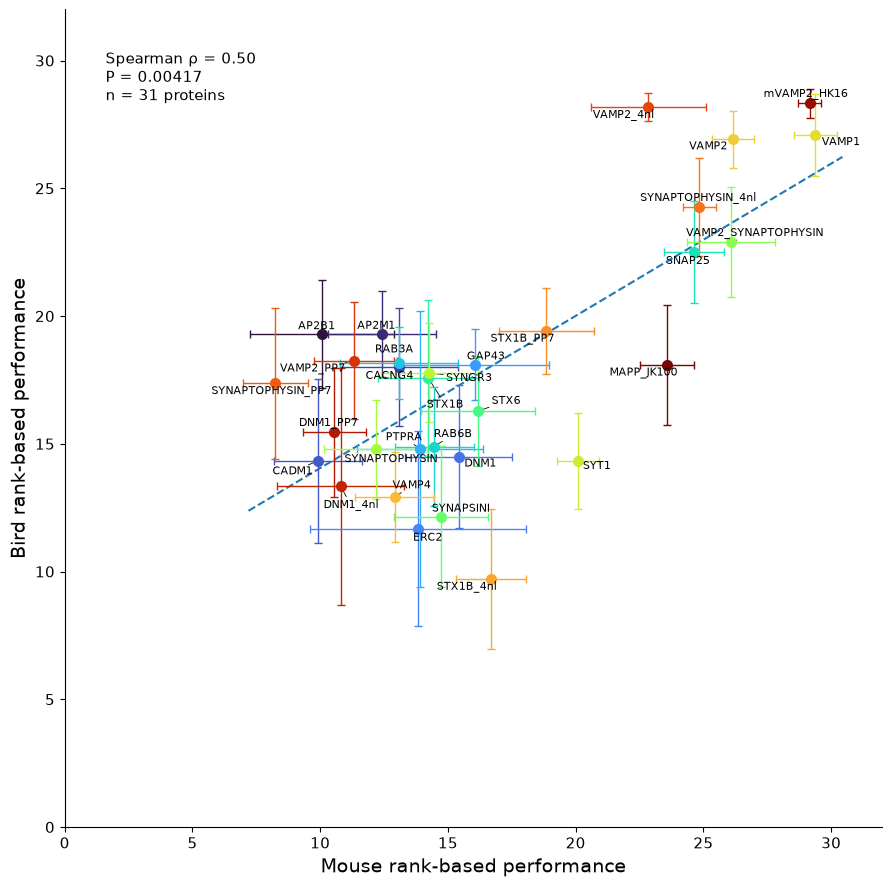


Files saved:
Mouse_vs_Bird_rank_based_performance_correlation.png
Mouse_vs_Bird_rank_based_performance_correlation.pdf
Mouse_vs_Bird_rank_based_performance_mean_SEM.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, spearmanr, linregress
from adjustText import adjust_text


df = pd.read_csv(r"E:\Data\Carrier_protein\Mouse\Second_Batch_Sequencing\thresholds\11012026_analysis\Mouse_bird.csv")


protein_cols = [
    col for col in df.columns
    if col not in ['Sample', 'Region']
]

df[protein_cols] = df[protein_cols].apply(
    pd.to_numeric,
    errors='coerce'
)


long_df = df.melt(
    id_vars=['Sample', 'Region'],
    value_vars=protein_cols,
    var_name='Protein',
    value_name='Value'
)


stats = (
    long_df
    .groupby(['Protein', 'Region'])['Value']
    .agg(
        mean='mean',
        sem='sem',
        n='count'
    )
    .reset_index()
)


mean_table = stats.pivot(
    index='Protein',
    columns='Region',
    values='mean'
)

sem_table = stats.pivot(
    index='Protein',
    columns='Region',
    values='sem'
)

n_table = stats.pivot(
    index='Protein',
    columns='Region',
    values='n'
)


plot_df = pd.DataFrame({

    'Mouse_mean_rank': mean_table.get('Mouse'),
    'Bird_mean_rank': mean_table.get('Bird'),

    'Mouse_sem': sem_table.get('Mouse'),
    'Bird_sem': sem_table.get('Bird'),

    'Mouse_n': n_table.get('Mouse'),
    'Bird_n': n_table.get('Bird')
})


plot_df = plot_df.dropna(
    subset=[
        'Mouse_mean_rank',
        'Bird_mean_rank'
    ]
).copy()


plot_df['Mouse_performance'] = (
    32 - plot_df['Mouse_mean_rank']
)

plot_df['Bird_performance'] = (
    32 - plot_df['Bird_mean_rank']
)


plot_df['Mouse_performance_sem'] = plot_df['Mouse_sem']
plot_df['Bird_performance_sem'] = plot_df['Bird_sem']


print('\nData used for plotting:')
print(plot_df)


pearson_r, pearson_p = pearsonr(
    plot_df['Mouse_performance'],
    plot_df['Bird_performance']
)


spearman_r, spearman_p = spearmanr(
    plot_df['Mouse_performance'],
    plot_df['Bird_performance']
)


print('\nPearson correlation')
print(f'r = {pearson_r:.4f}')
print(f'p = {pearson_p:.4g}')

print('\nSpearman correlation')
print(f'rho = {spearman_r:.4f}')
print(f'p = {spearman_p:.4g}')


reg = linregress(
    plot_df['Mouse_performance'],
    plot_df['Bird_performance']
)

print('\nLinear regression')
print(f'Slope = {reg.slope:.4f}')
print(f'Intercept = {reg.intercept:.4f}')
print(f'R² = {reg.rvalue**2:.4f}')


fig, ax = plt.subplots(
    figsize=(9, 9)
)


for protein, row in plot_df.iterrows():

    x = row['Mouse_performance']
    y = row['Bird_performance']

    xerr = row['Mouse_performance_sem']
    yerr = row['Bird_performance_sem']

    protein_color = protein_colors.get(
        protein,
        'black'
    )


    if pd.notna(xerr) and pd.notna(yerr):

        ax.errorbar(
            x,
            y,

            xerr=xerr,
            yerr=yerr,

            fmt='o',

            color=protein_color,

            ecolor=protein_color,

            markersize=7,

            capsize=3,
            capthick=1,

            elinewidth=1,

            zorder=3
        )


    else:

        xerr_plot = xerr if pd.notna(xerr) else None
        yerr_plot = yerr if pd.notna(yerr) else None

        ax.errorbar(
            x,
            y,

            xerr=xerr_plot,
            yerr=yerr_plot,

            fmt='o',

            color=protein_color,

            ecolor=protein_color,

            markersize=7,

            capsize=3,
            capthick=1,

            elinewidth=1,

            zorder=3
        )


x_min = plot_df['Mouse_performance'].min()
x_max = plot_df['Mouse_performance'].max()

x_padding = (x_max - x_min) * 0.05

x_line = np.linspace(
    x_min - x_padding,
    x_max + x_padding,
    300
)

y_line = (
    reg.slope * x_line
    + reg.intercept
)

ax.plot(
    x_line,
    y_line,
    '--',
    linewidth=1.5,
    zorder=1
)


texts = []

for protein, row in plot_df.iterrows():

    x = row['Mouse_performance']
    y = row['Bird_performance']

    text = ax.text(
        x,
        y,

        protein,

        fontsize=8,

        ha='center',
        va='center',

        zorder=4
    )

    texts.append(text)


adjust_text(

    texts,

    x=plot_df['Mouse_performance'].values,
    y=plot_df['Bird_performance'].values,

    ax=ax,

    expand=(1.4, 1.6),

    force_text=(0.8, 0.8),

    force_static=(0.5, 0.5),

    force_pull=(0.02, 0.02),

    arrowprops=dict(
        arrowstyle='-',
        lw=0.6
    )
)


ax.set_xlabel(
    'Mouse rank-based performance',
    fontsize=14
)

ax.set_ylabel(
    'Bird rank-based performance',
    fontsize=14
)


correlation_text = (

    f'Spearman ρ = {spearman_r:.2f}\n'
    f'P = {spearman_p:.3g}\n'
    f'n = {len(plot_df)} proteins'
)

ax.text(
    0.05,
    0.95,

    correlation_text,

    transform=ax.transAxes,

    ha='left',
    va='top',

    fontsize=11
)


all_values = np.concatenate([

    plot_df['Mouse_performance'].values,
    plot_df['Bird_performance'].values
])

all_sem = np.concatenate([

    plot_df['Mouse_performance_sem'].fillna(0).values,
    plot_df['Bird_performance_sem'].fillna(0).values
])


data_min = np.min(all_values - all_sem)
data_max = np.max(all_values + all_sem)

padding = max(
    1,
    (data_max - data_min) * 0.10
)

axis_min = max(
    0,
    data_min - padding
)

axis_max = min(
    32,
    data_max + padding
)

ax.set_xlim(
    0,
    32
)

ax.set_ylim(
    0,
    32
)

ax.set_aspect(
    'equal',
    adjustable='box'
)


ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.tick_params(
    axis='both',
    labelsize=11
)

plt.tight_layout()


plt.savefig(
    'Mouse_vs_Bird_rank_based_performance_correlation.png',
    dpi=300,
    bbox_inches='tight'
)

plt.savefig(
    'Mouse_vs_Bird_rank_based_performance_correlation.pdf',
    bbox_inches='tight'
)

plt.savefig(
    'Mouse_vs_Bird_rank_based_performance_correlation.eps',
    format='eps',
    bbox_inches='tight'
)

plt.show()

'''
plot_df.to_csv(
    'Mouse_vs_Bird_rank_based_performance_mean_SEM.csv'
)
'''

print('\nFiles saved:')
print('Mouse_vs_Bird_rank_based_performance_correlation.png')
print('Mouse_vs_Bird_rank_based_performance_correlation.pdf')
print('Mouse_vs_Bird_rank_based_performance_mean_SEM.csv')

### Bird


Data used for plotting:
                     RA_mean_rank  X_mean_rank     RA_sem     X_sem  RA_n  \
Protein                                                                     
AP2B1                    9.400000    13.750000   1.749286  3.473111     5   
AP2M1                   10.333333    11.714286   1.563472  1.375193     9   
CACNG4                  14.571429    10.833333   2.662412  1.661659     7   
CADM1                   14.750000    22.000000   4.767512  4.415880     4   
DNM1                    11.000000    18.800000   1.949359  3.839271     6   
DNM1_4nl                20.000000    21.500000  10.000000  6.500000     2   
DNM1_PP7                17.857143    16.125000   3.608380  3.130709     7   
ERC2                    18.250000    21.250000   5.406401  3.986958     4   
GAP43                   12.142857    13.222222   2.414525  0.968644     7   
MAPP_JK100              13.777778    12.900000   1.450841  2.363848     9   
PTPRA                   14.600000    21.500000   3.

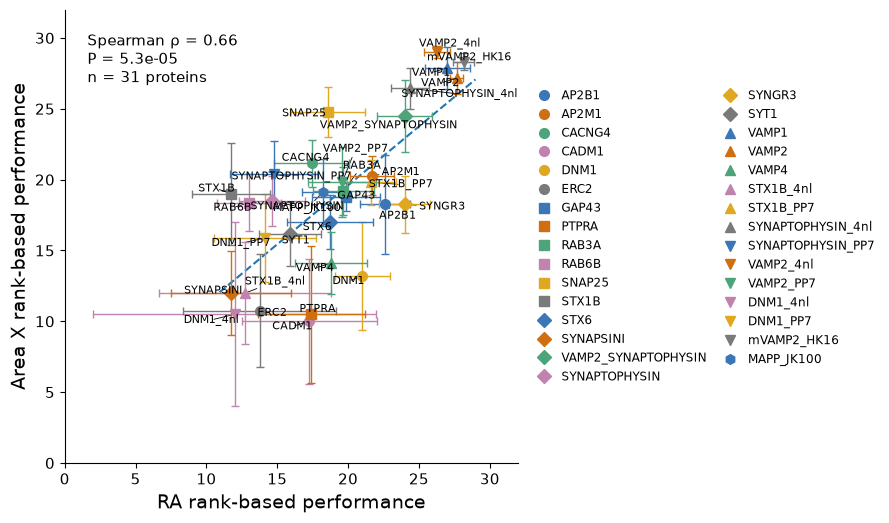


Files saved:
RA_vs_X_rank_based_performance_correlation.png
RA_vs_X_rank_based_performance_correlation.pdf
RA_vs_X_rank_based_performance_mean_SEM.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from scipy.stats import pearsonr, spearmanr, linregress
from adjustText import adjust_text


base_colors = {
    'blue':   '#3B77B6',
    'orange': '#D06F12',
    'green':  '#4DA37A',
    'pink':   '#C082AE',
    'yellow': '#E0A820',
    'gray':   '#7A7A7A'
}

protein_styles = {
    # Circle
    'AP2B1': {'color': base_colors['blue'],   'marker': 'o'},
    'AP2M1': {'color': base_colors['orange'], 'marker': 'o'},
    'CACNG4': {'color': base_colors['green'], 'marker': 'o'},
    'CADM1': {'color': base_colors['pink'],   'marker': 'o'},
    'DNM1': {'color': base_colors['yellow'],  'marker': 'o'},
    'ERC2': {'color': base_colors['gray'],    'marker': 'o'},

    # Square
    'GAP43': {'color': base_colors['blue'],   'marker': 's'},
    'PTPRA': {'color': base_colors['orange'], 'marker': 's'},
    'RAB3A': {'color': base_colors['green'],  'marker': 's'},
    'RAB6B': {'color': base_colors['pink'],   'marker': 's'},
    'SNAP25': {'color': base_colors['yellow'], 'marker': 's'},
    'STX1B': {'color': base_colors['gray'],   'marker': 's'},

    # Diamond
    'STX6': {'color': base_colors['blue'],   'marker': 'D'},
    'SYNAPSINI': {'color': base_colors['orange'], 'marker': 'D'},
    'VAMP2_SYNAPTOPHYSIN': {'color': base_colors['green'], 'marker': 'D'},
    'SYNAPTOPHYSIN': {'color': base_colors['pink'], 'marker': 'D'},
    'SYNGR3': {'color': base_colors['yellow'], 'marker': 'D'},
    'SYT1': {'color': base_colors['gray'],   'marker': 'D'},

    # Up triangle
    'VAMP1': {'color': base_colors['blue'],   'marker': '^'},
    'VAMP2': {'color': base_colors['orange'], 'marker': '^'},
    'VAMP4': {'color': base_colors['green'],  'marker': '^'},
    'STX1B_4nl': {'color': base_colors['pink'], 'marker': '^'},
    'STX1B_PP7': {'color': base_colors['yellow'], 'marker': '^'},
    'SYNAPTOPHYSIN_4nl': {'color': base_colors['gray'], 'marker': '^'},

    # Down triangle
    'SYNAPTOPHYSIN_PP7': {'color': base_colors['blue'],   'marker': 'v'},
    'VAMP2_4nl': {'color': base_colors['orange'], 'marker': 'v'},
    'VAMP2_PP7': {'color': base_colors['green'],  'marker': 'v'},
    'DNM1_4nl': {'color': base_colors['pink'],   'marker': 'v'},
    'DNM1_PP7': {'color': base_colors['yellow'], 'marker': 'v'},
    'mVAMP2_HK16': {'color': base_colors['gray'], 'marker': 'v'},

    # Hexagon
    'MAPP_JK100': {'color': base_colors['blue'], 'marker': 'h'}
}

protein_colors = {
    protein: style['color']
    for protein, style in protein_styles.items()
}

protein_markers = {
    protein: style['marker']
    for protein, style in protein_styles.items()
}



df = pd.read_csv(r"D:\Data\Carrier_protein\Bird\Thresholds\11012026_analysis\Bird_protein_rank_matrix_NOT_GT5.csv")


protein_cols = [
    col for col in df.columns
    if col not in ['Sample', 'Region']
]

df[protein_cols] = df[protein_cols].apply(
    pd.to_numeric,
    errors='coerce'
)


long_df = df.melt(
    id_vars=['Sample', 'Region'],
    value_vars=protein_cols,
    var_name='Protein',
    value_name='Value'
)


stats = (
    long_df
    .groupby(['Protein', 'Region'])['Value']
    .agg(
        mean='mean',
        sem='sem',
        n='count'
    )
    .reset_index()
)


mean_table = stats.pivot(
    index='Protein',
    columns='Region',
    values='mean'
)

sem_table = stats.pivot(
    index='Protein',
    columns='Region',
    values='sem'
)

n_table = stats.pivot(
    index='Protein',
    columns='Region',
    values='n'
)


plot_df = pd.DataFrame({

    'RA_mean_rank': mean_table.get('RA'),
    'X_mean_rank': mean_table.get('X'),

    'RA_sem': sem_table.get('RA'),
    'X_sem': sem_table.get('X'),

    'RA_n': n_table.get('RA'),
    'X_n': n_table.get('X')
})


plot_df = plot_df.dropna(
    subset=[
        'RA_mean_rank',
        'X_mean_rank'
    ]
).copy()


plot_df['RA_performance'] = (
    32 - plot_df['RA_mean_rank']
)

plot_df['X_performance'] = (
    32 - plot_df['X_mean_rank']
)


plot_df['RA_performance_sem'] = plot_df['RA_sem']
plot_df['X_performance_sem'] = plot_df['X_sem']


print('\nData used for plotting:')
print(plot_df)


pearson_r, pearson_p = pearsonr(
    plot_df['RA_performance'],
    plot_df['X_performance']
)

spearman_r, spearman_p = spearmanr(
    plot_df['RA_performance'],
    plot_df['X_performance']
)


print('\nPearson correlation')
print(f'r = {pearson_r:.4f}')
print(f'p = {pearson_p:.4g}')

print('\nSpearman correlation')
print(f'rho = {spearman_r:.4f}')
print(f'p = {spearman_p:.4g}')


reg = linregress(
    plot_df['RA_performance'],
    plot_df['X_performance']
)

print('\nLinear regression')
print(f'Slope = {reg.slope:.4f}')
print(f'Intercept = {reg.intercept:.4f}')
print(f'R² = {reg.rvalue**2:.4f}')


fig, ax = plt.subplots(
    figsize=(9, 9)
)


for protein, row in plot_df.iterrows():

    x = row['RA_performance']
    y = row['X_performance']

    xerr = row['RA_performance_sem']
    yerr = row['X_performance_sem']

    protein_color = protein_colors[protein]
    protein_marker = protein_markers[protein]


    if pd.notna(xerr) and pd.notna(yerr):

        ax.errorbar(
            x,
            y,

            xerr=xerr,
            yerr=yerr,

            fmt=protein_marker,

            color=protein_color,

            ecolor=protein_color,

            markersize=7,

            capsize=3,
            capthick=1,

            elinewidth=1,

            zorder=3
        )


    else:

        xerr_plot = xerr if pd.notna(xerr) else None
        yerr_plot = yerr if pd.notna(yerr) else None

        ax.errorbar(
            x,
            y,

            xerr=xerr_plot,
            yerr=yerr_plot,

            fmt=protein_marker,

            color=protein_color,

            ecolor=protein_color,

            markersize=7,

            capsize=3,
            capthick=1,

            elinewidth=1,

            zorder=3
        )


x_min = plot_df['RA_performance'].min()
x_max = plot_df['RA_performance'].max()

x_padding = (x_max - x_min) * 0.05

x_line = np.linspace(
    x_min - x_padding,
    x_max + x_padding,
    300
)

y_line = (
    reg.slope * x_line
    + reg.intercept
)

ax.plot(
    x_line,
    y_line,
    '--',
    linewidth=1.5,
    zorder=1
)


texts = []

for protein, row in plot_df.iterrows():

    x = row['RA_performance']
    y = row['X_performance']

    text = ax.text(
        x,
        y,

        protein,

        fontsize=8,

        ha='center',
        va='center',

        zorder=4
    )

    texts.append(text)


adjust_text(

    texts,

    x=plot_df['RA_performance'].values,
    y=plot_df['X_performance'].values,

    ax=ax,

    expand=(1.4, 1.6),

    force_text=(0.8, 0.8),

    force_static=(0.5, 0.5),

    force_pull=(0.02, 0.02),

    arrowprops=dict(
        arrowstyle='-',
        lw=0.6
    )
)


ax.set_xlabel(
    'RA rank-based performance',
    fontsize=14
)

ax.set_ylabel(
    'Area X rank-based performance',
    fontsize=14
)


correlation_text = (

    f'Spearman ρ = {spearman_r:.2f}\n'
    f'P = {spearman_p:.3g}\n'
    f'n = {len(plot_df)} proteins'
)

ax.text(
    0.05,
    0.95,

    correlation_text,

    transform=ax.transAxes,

    ha='left',
    va='top',

    fontsize=11
)


all_values = np.concatenate([

    plot_df['RA_performance'].values,
    plot_df['X_performance'].values
])

all_sem = np.concatenate([

    plot_df['RA_performance_sem'].fillna(0).values,
    plot_df['X_performance_sem'].fillna(0).values
])


data_min = np.min(all_values - all_sem)
data_max = np.max(all_values + all_sem)

padding = max(
    1,
    (data_max - data_min) * 0.10
)

axis_min = max(
    0,
    data_min - padding
)

axis_max = min(
    32,
    data_max + padding
)

ax.set_xlim(
    axis_min,
    axis_max
)

ax.set_ylim(
    axis_min,
    axis_max
)

ax.set_aspect(
    'equal',
    adjustable='box'
)


ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.tick_params(
    axis='both',
    labelsize=11
)


legend_handles = []

for protein, style in protein_styles.items():

    if protein not in plot_df.index:
        continue

    legend_handles.append(
        Line2D(
            [0],
            [0],
            linestyle='None',
            marker=style['marker'],
            color=style['color'],
            markerfacecolor=style['color'],
            markeredgecolor=style['color'],
            markersize=7,
            label=protein
        )
    )

ax.legend(
    handles=legend_handles,
    loc='center left',
    bbox_to_anchor=(1.02, 0.5),
    ncol=2,
    frameon=False,
    fontsize=8.5,
    handletextpad=0.5,
    columnspacing=1.0,
    borderaxespad=0.0
)


plt.tight_layout()


plt.savefig(
    'RA_vs_X_rank_based_performance_correlation.png',
    dpi=300,
    bbox_inches='tight'
)

plt.savefig(
    'RA_vs_X_rank_based_performance_correlation.pdf',
    bbox_inches='tight'
)

plt.savefig(
        'RA_vs_X_rank_based_performance_correlation.eps',
        format='eps',
        bbox_inches='tight') 

plt.show()

'''
plot_df.to_csv(
    'RA_vs_X_rank_based_performance_mean_SEM.csv'
)
'''

print('\nFiles saved:')
print('RA_vs_X_rank_based_performance_correlation.png')
print('RA_vs_X_rank_based_performance_correlation.pdf')
print('RA_vs_X_rank_based_performance_mean_SEM.csv')

### mouse


Regions found:
Medulla
SNr
Thalamus

Region pairs:
('Medulla', 'SNr')
('Medulla', 'Thalamus')
('SNr', 'Thalamus')

Medulla vs SNr

Proteins used:
                     Medulla_mean_rank  SNr_mean_rank  Medulla_performance  \
Protein                                                                      
AP2B1                        14.500000      16.666667            17.500000   
AP2M1                        15.200000      19.222222            16.800000   
CACNG4                       14.666667      16.111111            17.333333   
CADM1                        19.000000      17.181818            13.000000   
DNM1                         14.428571      17.000000            17.571429   
DNM1_4nl                     19.200000      16.666667            12.800000   
DNM1_PP7                     16.375000      14.250000            15.625000   
ERC2                         10.000000       9.000000            22.000000   
GAP43                        13.400000      15.166667            18.60000

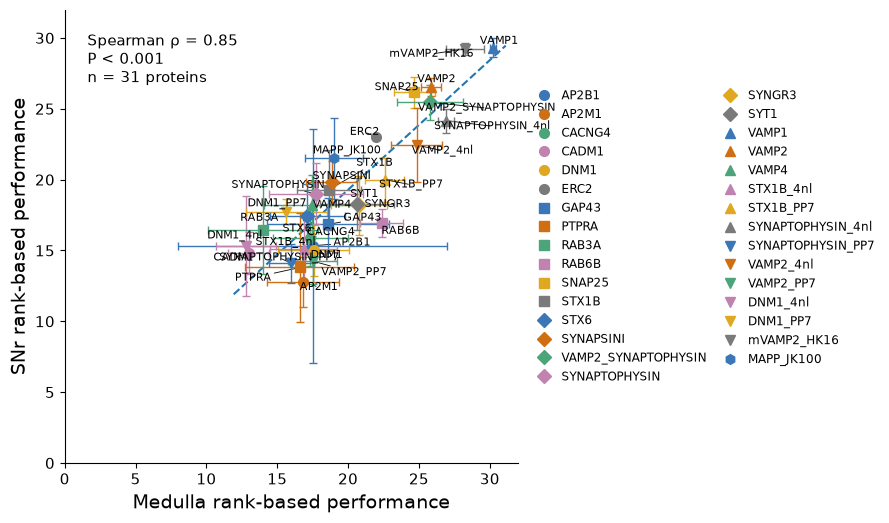


Medulla vs Thalamus

Proteins used:
                     Medulla_mean_rank  Thalamus_mean_rank  \
Protein                                                      
AP2B1                        14.500000           21.090909   
AP2M1                        15.200000           18.166667   
CACNG4                       14.666667           18.363636   
CADM1                        19.000000           22.000000   
DNM1                         14.428571           15.750000   
DNM1_4nl                     19.200000           21.000000   
DNM1_PP7                     16.375000           22.000000   
ERC2                         10.000000           21.250000   
GAP43                        13.400000           20.181818   
MAPP_JK100                   13.000000            8.500000   
PTPRA                        15.400000           18.400000   
RAB3A                        18.000000           17.166667   
RAB6B                         9.636364           16.750000   
SNAP25                        7.3

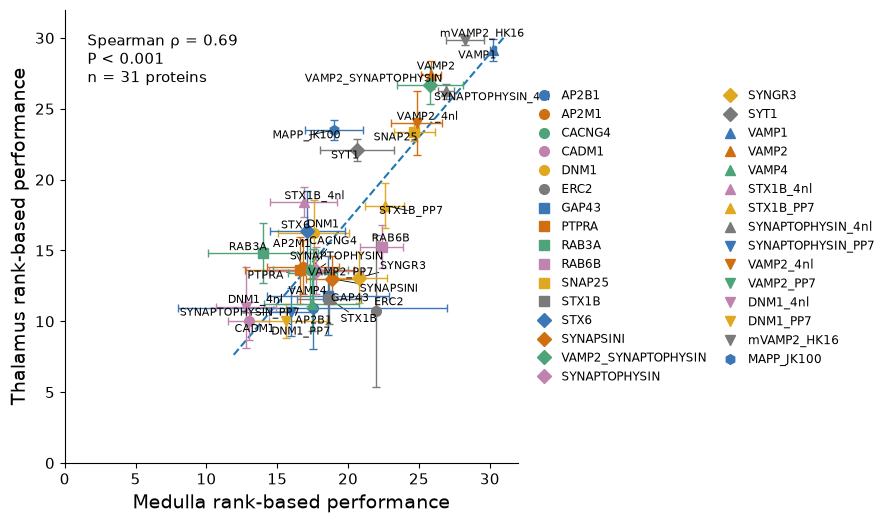


SNr vs Thalamus

Proteins used:
                     SNr_mean_rank  Thalamus_mean_rank  SNr_performance  \
Protein                                                                   
AP2B1                    16.666667           21.090909        15.333333   
AP2M1                    19.222222           18.166667        12.777778   
CACNG4                   16.111111           18.363636        15.888889   
CADM1                    17.181818           22.000000        14.818182   
DNM1                     17.000000           15.750000        15.000000   
DNM1_4nl                 16.666667           21.000000        15.333333   
DNM1_PP7                 14.250000           22.000000        17.750000   
ERC2                      9.000000           21.250000        23.000000   
GAP43                    15.166667           20.181818        16.833333   
MAPP_JK100               10.500000            8.500000        21.500000   
PTPRA                    18.200000           18.400000        13.80

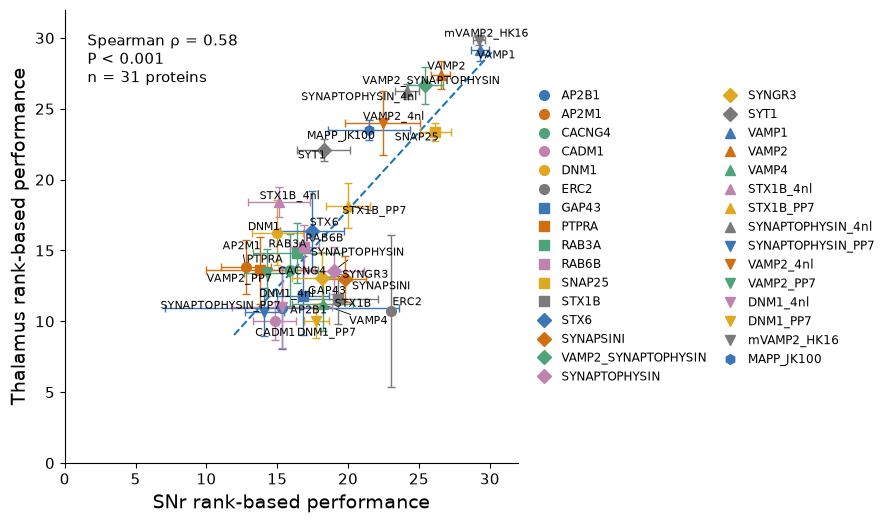


All analyses finished

Correlation summary:
  Region_X  Region_Y  N_proteins  Pearson_r     Pearson_p  Spearman_rho  \
0  Medulla       SNr          31   0.887850  2.745119e-11      0.848457   
1  Medulla  Thalamus          31   0.835258  5.088285e-09      0.692277   
2      SNr  Thalamus          31   0.803277  5.352197e-08      0.578141   

     Spearman_p  Regression_slope  Regression_intercept  Regression_R2  
0  1.657905e-09          0.914277              1.003009       0.788278  
1  1.598592e-05          1.175097             -6.379338       0.697656  
2  6.582814e-04          1.097440             -4.079323       0.645254  


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, spearmanr, linregress
from adjustText import adjust_text
from itertools import combinations
from matplotlib.lines import Line2D


base_colors = {
    'blue':   '#3B77B6',
    'orange': '#D06F12',
    'green':  '#4DA37A',
    'pink':   '#C082AE',
    'yellow': '#E0A820',
    'gray':   '#7A7A7A'
}

protein_styles = {
    # Circle
    'AP2B1': {'color': base_colors['blue'],   'marker': 'o'},
    'AP2M1': {'color': base_colors['orange'], 'marker': 'o'},
    'CACNG4': {'color': base_colors['green'], 'marker': 'o'},
    'CADM1': {'color': base_colors['pink'],   'marker': 'o'},
    'DNM1': {'color': base_colors['yellow'],  'marker': 'o'},
    'ERC2': {'color': base_colors['gray'],    'marker': 'o'},

    # Square
    'GAP43': {'color': base_colors['blue'],   'marker': 's'},
    'PTPRA': {'color': base_colors['orange'], 'marker': 's'},
    'RAB3A': {'color': base_colors['green'],  'marker': 's'},
    'RAB6B': {'color': base_colors['pink'],   'marker': 's'},
    'SNAP25': {'color': base_colors['yellow'], 'marker': 's'},
    'STX1B': {'color': base_colors['gray'],   'marker': 's'},

    # Diamond
    'STX6': {'color': base_colors['blue'],   'marker': 'D'},
    'SYNAPSINI': {'color': base_colors['orange'], 'marker': 'D'},
    'VAMP2_SYNAPTOPHYSIN': {'color': base_colors['green'], 'marker': 'D'},
    'SYNAPTOPHYSIN': {'color': base_colors['pink'], 'marker': 'D'},
    'SYNGR3': {'color': base_colors['yellow'], 'marker': 'D'},
    'SYT1': {'color': base_colors['gray'],   'marker': 'D'},

    # Up triangle
    'VAMP1': {'color': base_colors['blue'],   'marker': '^'},
    'VAMP2': {'color': base_colors['orange'], 'marker': '^'},
    'VAMP4': {'color': base_colors['green'],  'marker': '^'},
    'STX1B_4nl': {'color': base_colors['pink'], 'marker': '^'},
    'STX1B_PP7': {'color': base_colors['yellow'], 'marker': '^'},
    'SYNAPTOPHYSIN_4nl': {'color': base_colors['gray'], 'marker': '^'},

    # Down triangle
    'SYNAPTOPHYSIN_PP7': {'color': base_colors['blue'],   'marker': 'v'},
    'VAMP2_4nl': {'color': base_colors['orange'], 'marker': 'v'},
    'VAMP2_PP7': {'color': base_colors['green'],  'marker': 'v'},
    'DNM1_4nl': {'color': base_colors['pink'],   'marker': 'v'},
    'DNM1_PP7': {'color': base_colors['yellow'], 'marker': 'v'},
    'mVAMP2_HK16': {'color': base_colors['gray'], 'marker': 'v'},

    # Hexagon
    'MAPP_JK100': {'color': base_colors['blue'], 'marker': 'h'}
}

protein_colors = {
    protein: style['color']
    for protein, style in protein_styles.items()
}

protein_markers = {
    protein: style['marker']
    for protein, style in protein_styles.items()
}


df = pd.read_csv(r"E:\Data\Carrier_protein\Mouse\Second_Batch_Sequencing\thresholds\11012026_analysis\Mouse_protein_rank_matrix_NOT_GT5.csv")


protein_cols = [
    col for col in df.columns
    if col not in ['Sample', 'Region']
]

df[protein_cols] = df[protein_cols].apply(
    pd.to_numeric,
    errors='coerce'
)


long_df = df.melt(
    id_vars=['Sample', 'Region'],
    value_vars=protein_cols,
    var_name='Protein',
    value_name='Value'
)


stats = (
    long_df
    .groupby(['Protein', 'Region'])['Value']
    .agg(
        mean_rank='mean',
        sem='sem',
        n='count'
    )
    .reset_index()
)


stats['performance'] = 32 - stats['mean_rank']

stats.to_csv(
    'Mouse_all_regions_mean_SEM_performance.csv',
    index=False
)


performance_table = stats.pivot(
    index='Protein',
    columns='Region',
    values='performance'
)

mean_rank_table = stats.pivot(
    index='Protein',
    columns='Region',
    values='mean_rank'
)

sem_table = stats.pivot(
    index='Protein',
    columns='Region',
    values='sem'
)

n_table = stats.pivot(
    index='Protein',
    columns='Region',
    values='n'
)


regions = df['Region'].dropna().unique().tolist()

print('\nRegions found:')
for region in regions:
    print(region)



region_pairs = list(combinations(regions, 2))

print('\nRegion pairs:')
for pair in region_pairs:
    print(pair)



correlation_results = []


for region_x, region_y in region_pairs:

    print('\n=======================================')
    print(f'{region_x} vs {region_y}')
    print('=======================================')


    plot_df = pd.DataFrame({

        f'{region_x}_mean_rank':
            mean_rank_table[region_x],

        f'{region_y}_mean_rank':
            mean_rank_table[region_y],

        f'{region_x}_performance':
            performance_table[region_x],

        f'{region_y}_performance':
            performance_table[region_y],

        f'{region_x}_sem':
            sem_table[region_x],

        f'{region_y}_sem':
            sem_table[region_y],

        f'{region_x}_n':
            n_table[region_x],

        f'{region_y}_n':
            n_table[region_y]

    })


    plot_df = plot_df.dropna(
        subset=[
            f'{region_x}_performance',
            f'{region_y}_performance'
        ]
    ).copy()



    print('\nProteins used:')
    print(plot_df)

    if len(plot_df) < 2:

        print(
            f'Not enough proteins for '
            f'{region_x} vs {region_y}.'
        )

        continue


    x = plot_df[
        f'{region_x}_performance'
    ].values

    y = plot_df[
        f'{region_y}_performance'
    ].values


    pearson_r, pearson_p = pearsonr(
        x,
        y
    )


    spearman_r, spearman_p = spearmanr(
        x,
        y
    )


    regression = linregress(
        x,
        y
    )

    slope = regression.slope
    intercept = regression.intercept
    r_squared = regression.rvalue ** 2


    print('\nPearson:')
    print(f'r = {pearson_r:.4f}')
    print(f'p = {pearson_p:.4g}')

    print('\nSpearman:')
    print(f'rho = {spearman_r:.4f}')
    print(f'p = {spearman_p:.4g}')

    print('\nLinear regression:')
    print(f'slope = {slope:.4f}')
    print(f'intercept = {intercept:.4f}')
    print(f'R² = {r_squared:.4f}')

    correlation_results.append({

        'Region_X': region_x,
        'Region_Y': region_y,

        'N_proteins': len(plot_df),

        'Pearson_r': pearson_r,
        'Pearson_p': pearson_p,

        'Spearman_rho': spearman_r,
        'Spearman_p': spearman_p,

        'Regression_slope': slope,
        'Regression_intercept': intercept,
        'Regression_R2': r_squared

    })


    fig, ax = plt.subplots(
        figsize=(9, 9)
    )


    for protein, row in plot_df.iterrows():

        x_value = row[
            f'{region_x}_performance'
        ]

        y_value = row[
            f'{region_y}_performance'
        ]

        x_sem = row[
            f'{region_x}_sem'
        ]

        y_sem = row[
            f'{region_y}_sem'
        ]


        xerr_plot = (
            x_sem
            if pd.notna(x_sem)
            else None
        )

        yerr_plot = (
            y_sem
            if pd.notna(y_sem)
            else None
        )


        protein_color = protein_colors.get(
            protein,
            'black'
        )

        protein_marker = protein_markers.get(
            protein,
            'o'
        )


        ax.errorbar(

            x_value,
            y_value,

            xerr=xerr_plot,
            yerr=yerr_plot,

            fmt=protein_marker,

            color=protein_color,

            ecolor=protein_color,

            markersize=7,

            capsize=3,
            capthick=1,

            elinewidth=1,

            zorder=3
        )


    x_min = np.min(x)
    x_max = np.max(x)

    x_padding = max(
        0.5,
        (x_max - x_min) * 0.05
    )

    x_line = np.linspace(
        x_min - x_padding,
        x_max + x_padding,
        300
    )

    y_line = (
        slope * x_line
        + intercept
    )


    ax.plot(
        x_line,
        y_line,

        '--',

        linewidth=1.5,

        zorder=1
    )


    texts = []

    for protein, row in plot_df.iterrows():

        x_value = row[
            f'{region_x}_performance'
        ]

        y_value = row[
            f'{region_y}_performance'
        ]


        text = ax.text(

            x_value,
            y_value,

            protein,

            fontsize=8,

            ha='center',
            va='center',

            zorder=4
        )

        texts.append(text)


    adjust_text(

        texts,

        x=x,
        y=y,

        ax=ax,

        expand=(1.6, 1.8),

        force_text=(0.8, 0.8),

        force_static=(0.5, 0.5),

        force_pull=(0.02, 0.02),

        arrowprops=dict(
            arrowstyle='-',
            lw=0.6
        )
    )


    ax.set_xlabel(
        f'{region_x} rank-based performance',
        fontsize=14
    )

    ax.set_ylabel(
        f'{region_y} rank-based performance',
        fontsize=14
    )


    if spearman_p < 0.001:

        p_text = 'P < 0.001'

    else:

        p_text = f'P = {spearman_p:.3f}'


    correlation_text = (

        f'Spearman ρ = {spearman_r:.2f}\n'
        f'{p_text}\n'
        f'n = {len(plot_df)} proteins'
    )


    ax.text(

        0.05,
        0.95,

        correlation_text,

        transform=ax.transAxes,

        ha='left',
        va='top',

        fontsize=11
    )


    ax.set_xlim(
        0,
        32
    )

    ax.set_ylim(
        0,
        32
    )

    ax.set_aspect(
        'equal',
        adjustable='box'
    )


    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    ax.tick_params(
        axis='both',
        labelsize=11
    )


    legend_handles = []

    for protein, style in protein_styles.items():

        if protein not in plot_df.index:
            continue

        legend_handles.append(
            Line2D(
                [0],
                [0],
                linestyle='None',
                marker=style['marker'],
                color=style['color'],
                markerfacecolor=style['color'],
                markeredgecolor=style['color'],
                markersize=7,
                label=protein
            )
        )

    ax.legend(
        handles=legend_handles,
        loc='center left',
        bbox_to_anchor=(1.02, 0.5),
        ncol=2,
        frameon=False,
        fontsize=8.5,
        handletextpad=0.5,
        columnspacing=1.0,
        borderaxespad=0.0
    )

    plt.tight_layout()


    safe_x = region_x.replace(' ', '_')
    safe_y = region_y.replace(' ', '_')

    base_name = (
        f'{safe_x}_vs_{safe_y}_'
        f'rank_based_performance'
    )


    plt.savefig(

        f'{base_name}.png',

        dpi=300,

        bbox_inches='tight'
    )


    plt.savefig(

        f'{base_name}.pdf',

        bbox_inches='tight'
    )


    plot_df.to_csv(

        f'{base_name}_mean_SEM.csv'
    )

    plt.savefig(
        f'{base_name}.eps',
        format='eps',
        bbox_inches='tight') 

    plt.show()


correlation_results_df = pd.DataFrame(
    correlation_results
)
'''
correlation_results_df.to_csv(
    'Mouse_all_pairwise_region_correlations.csv',
    index=False
)
'''

print('\n=======================================')
print('All analyses finished')
print('=======================================')

print('\nCorrelation summary:')
print(correlation_results_df)


Data used for plotting:
                     Mouse_mean_rank  Bird_mean_rank  Mouse_sem  Bird_sem  \
Protein                                                                     
AP2B1                      21.916667       12.714286   2.816236  2.112483   
AP2M1                      19.583333       12.700000   2.101436  1.686877   
CACNG4                     18.916667       14.000000   2.317451  2.321398   
CADM1                      22.083333       17.666667   1.725295  3.221456   
DNM1                       16.583333       17.500000   2.105038  2.815772   
DNM1_4nl                   21.200000       18.666667   2.475659  4.630815   
DNM1_PP7                   21.454545       16.545455   1.231139  2.523935   
ERC2                       18.166667       20.333333   4.238055  3.818086   
GAP43                      15.923077       13.900000   2.896642  1.378002   
MAPP_JK100                  8.416667       13.909091   1.062147  2.348905   
PTPRA                      18.090909       17.20000

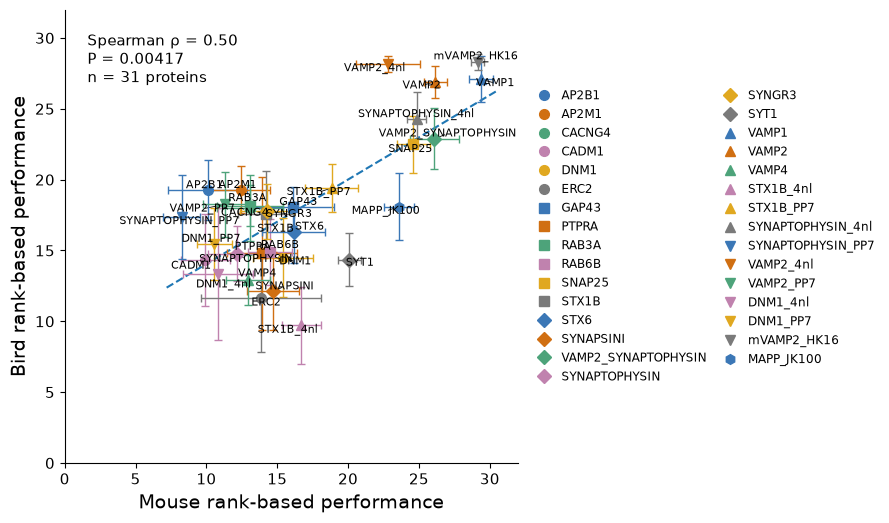


Files saved:
Mouse_vs_Bird_rank_based_performance_correlation.png
Mouse_vs_Bird_rank_based_performance_correlation.pdf
Mouse_vs_Bird_rank_based_performance_mean_SEM.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, spearmanr, linregress
from adjustText import adjust_text
from matplotlib.lines import Line2D


base_colors = {
    'blue':   '#3B77B6',
    'orange': '#D06F12',
    'green':  '#4DA37A',
    'pink':   '#C082AE',
    'yellow': '#E0A820',
    'gray':   '#7A7A7A'
}

protein_styles = {
    # Circle
    'AP2B1': {'color': base_colors['blue'],   'marker': 'o'},
    'AP2M1': {'color': base_colors['orange'], 'marker': 'o'},
    'CACNG4': {'color': base_colors['green'], 'marker': 'o'},
    'CADM1': {'color': base_colors['pink'],   'marker': 'o'},
    'DNM1': {'color': base_colors['yellow'],  'marker': 'o'},
    'ERC2': {'color': base_colors['gray'],    'marker': 'o'},

    # Square
    'GAP43': {'color': base_colors['blue'],   'marker': 's'},
    'PTPRA': {'color': base_colors['orange'], 'marker': 's'},
    'RAB3A': {'color': base_colors['green'],  'marker': 's'},
    'RAB6B': {'color': base_colors['pink'],   'marker': 's'},
    'SNAP25': {'color': base_colors['yellow'], 'marker': 's'},
    'STX1B': {'color': base_colors['gray'],   'marker': 's'},

    # Diamond
    'STX6': {'color': base_colors['blue'],   'marker': 'D'},
    'SYNAPSINI': {'color': base_colors['orange'], 'marker': 'D'},
    'VAMP2_SYNAPTOPHYSIN': {'color': base_colors['green'], 'marker': 'D'},
    'SYNAPTOPHYSIN': {'color': base_colors['pink'], 'marker': 'D'},
    'SYNGR3': {'color': base_colors['yellow'], 'marker': 'D'},
    'SYT1': {'color': base_colors['gray'],   'marker': 'D'},

    # Up triangle
    'VAMP1': {'color': base_colors['blue'],   'marker': '^'},
    'VAMP2': {'color': base_colors['orange'], 'marker': '^'},
    'VAMP4': {'color': base_colors['green'],  'marker': '^'},
    'STX1B_4nl': {'color': base_colors['pink'], 'marker': '^'},
    'STX1B_PP7': {'color': base_colors['yellow'], 'marker': '^'},
    'SYNAPTOPHYSIN_4nl': {'color': base_colors['gray'], 'marker': '^'},

    # Down triangle
    'SYNAPTOPHYSIN_PP7': {'color': base_colors['blue'],   'marker': 'v'},
    'VAMP2_4nl': {'color': base_colors['orange'], 'marker': 'v'},
    'VAMP2_PP7': {'color': base_colors['green'],  'marker': 'v'},
    'DNM1_4nl': {'color': base_colors['pink'],   'marker': 'v'},
    'DNM1_PP7': {'color': base_colors['yellow'], 'marker': 'v'},
    'mVAMP2_HK16': {'color': base_colors['gray'], 'marker': 'v'},

    # Hexagon
    'MAPP_JK100': {'color': base_colors['blue'], 'marker': 'h'}
}

protein_colors = {
    protein: style['color']
    for protein, style in protein_styles.items()
}

protein_markers = {
    protein: style['marker']
    for protein, style in protein_styles.items()
}


df = pd.read_csv(r"E:\Data\Carrier_protein\Mouse\Second_Batch_Sequencing\thresholds\11012026_analysis\Mouse_bird.csv")


protein_cols = [
    col for col in df.columns
    if col not in ['Sample', 'Region']
]

df[protein_cols] = df[protein_cols].apply(
    pd.to_numeric,
    errors='coerce'
)


long_df = df.melt(
    id_vars=['Sample', 'Region'],
    value_vars=protein_cols,
    var_name='Protein',
    value_name='Value'
)


stats = (
    long_df
    .groupby(['Protein', 'Region'])['Value']
    .agg(
        mean='mean',
        sem='sem',
        n='count'
    )
    .reset_index()
)


mean_table = stats.pivot(
    index='Protein',
    columns='Region',
    values='mean'
)

sem_table = stats.pivot(
    index='Protein',
    columns='Region',
    values='sem'
)

n_table = stats.pivot(
    index='Protein',
    columns='Region',
    values='n'
)


plot_df = pd.DataFrame({

    'Mouse_mean_rank': mean_table.get('Mouse'),
    'Bird_mean_rank': mean_table.get('Bird'),

    'Mouse_sem': sem_table.get('Mouse'),
    'Bird_sem': sem_table.get('Bird'),

    'Mouse_n': n_table.get('Mouse'),
    'Bird_n': n_table.get('Bird')
})


plot_df = plot_df.dropna(
    subset=[
        'Mouse_mean_rank',
        'Bird_mean_rank'
    ]
).copy()


plot_df['Mouse_performance'] = (
    32 - plot_df['Mouse_mean_rank']
)

plot_df['Bird_performance'] = (
    32 - plot_df['Bird_mean_rank']
)


plot_df['Mouse_performance_sem'] = plot_df['Mouse_sem']
plot_df['Bird_performance_sem'] = plot_df['Bird_sem']


print('\nData used for plotting:')
print(plot_df)


pearson_r, pearson_p = pearsonr(
    plot_df['Mouse_performance'],
    plot_df['Bird_performance']
)


spearman_r, spearman_p = spearmanr(
    plot_df['Mouse_performance'],
    plot_df['Bird_performance']
)


print('\nPearson correlation')
print(f'r = {pearson_r:.4f}')
print(f'p = {pearson_p:.4g}')

print('\nSpearman correlation')
print(f'rho = {spearman_r:.4f}')
print(f'p = {spearman_p:.4g}')


reg = linregress(
    plot_df['Mouse_performance'],
    plot_df['Bird_performance']
)

print('\nLinear regression')
print(f'Slope = {reg.slope:.4f}')
print(f'Intercept = {reg.intercept:.4f}')
print(f'R² = {reg.rvalue**2:.4f}')


fig, ax = plt.subplots(
    figsize=(9, 9)
)


for protein, row in plot_df.iterrows():

    x = row['Mouse_performance']
    y = row['Bird_performance']

    xerr = row['Mouse_performance_sem']
    yerr = row['Bird_performance_sem']

    protein_color = protein_colors.get(
        protein,
        'black'
    )

    protein_marker = protein_markers.get(
        protein,
        'o'
    )


    if pd.notna(xerr) and pd.notna(yerr):

        ax.errorbar(
            x,
            y,

            xerr=xerr,
            yerr=yerr,

            fmt=protein_marker,

            color=protein_color,

            ecolor=protein_color,

            markersize=7,

            capsize=3,
            capthick=1,

            elinewidth=1,

            zorder=3
        )


    else:

        xerr_plot = xerr if pd.notna(xerr) else None
        yerr_plot = yerr if pd.notna(yerr) else None

        ax.errorbar(
            x,
            y,

            xerr=xerr_plot,
            yerr=yerr_plot,

            fmt=protein_marker,

            color=protein_color,

            ecolor=protein_color,

            markersize=7,

            capsize=3,
            capthick=1,

            elinewidth=1,

            zorder=3
        )


x_min = plot_df['Mouse_performance'].min()
x_max = plot_df['Mouse_performance'].max()

x_padding = (x_max - x_min) * 0.05

x_line = np.linspace(
    x_min - x_padding,
    x_max + x_padding,
    300
)

y_line = (
    reg.slope * x_line
    + reg.intercept
)

ax.plot(
    x_line,
    y_line,
    '--',
    linewidth=1.5,
    zorder=1
)


texts = []

for protein, row in plot_df.iterrows():

    x = row['Mouse_performance']
    y = row['Bird_performance']

    text = ax.text(
        x,
        y,

        protein,

        fontsize=8,

        ha='center',
        va='center',

        zorder=4
    )

    texts.append(text)


adjust_text(

    texts,

    x=plot_df['Mouse_performance'].values,
    y=plot_df['Bird_performance'].values,

    ax=ax,

    expand=(1.4, 1.6),

    force_text=(0.8, 0.8),

    force_static=(0.5, 0.5),

    force_pull=(0.02, 0.02),

    arrowprops=dict(
        arrowstyle='-',
        lw=0.6
    )
)


ax.set_xlabel(
    'Mouse rank-based performance',
    fontsize=14
)

ax.set_ylabel(
    'Bird rank-based performance',
    fontsize=14
)


correlation_text = (

    f'Spearman ρ = {spearman_r:.2f}\n'
    f'P = {spearman_p:.3g}\n'
    f'n = {len(plot_df)} proteins'
)

ax.text(
    0.05,
    0.95,

    correlation_text,

    transform=ax.transAxes,

    ha='left',
    va='top',

    fontsize=11
)


all_values = np.concatenate([

    plot_df['Mouse_performance'].values,
    plot_df['Bird_performance'].values
])

all_sem = np.concatenate([

    plot_df['Mouse_performance_sem'].fillna(0).values,
    plot_df['Bird_performance_sem'].fillna(0).values
])


data_min = np.min(all_values - all_sem)
data_max = np.max(all_values + all_sem)

padding = max(
    1,
    (data_max - data_min) * 0.10
)

axis_min = max(
    0,
    data_min - padding
)

axis_max = min(
    32,
    data_max + padding
)

ax.set_xlim(
    0,
    32
)

ax.set_ylim(
    0,
    32
)

ax.set_aspect(
    'equal',
    adjustable='box'
)


ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.tick_params(
    axis='both',
    labelsize=11
)


legend_handles = []

for protein, style in protein_styles.items():

    if protein not in plot_df.index:
        continue

    legend_handles.append(
        Line2D(
            [0],
            [0],
            linestyle='None',
            marker=style['marker'],
            color=style['color'],
            markerfacecolor=style['color'],
            markeredgecolor=style['color'],
            markersize=7,
            label=protein
        )
    )

ax.legend(
    handles=legend_handles,
    loc='center left',
    bbox_to_anchor=(1.02, 0.5),
    ncol=2,
    frameon=False,
    fontsize=8.5,
    handletextpad=0.5,
    columnspacing=1.0,
    borderaxespad=0.0
)

plt.tight_layout()


plt.savefig(
    'Mouse_vs_Bird_rank_based_performance_correlation.png',
    dpi=300,
    bbox_inches='tight'
)

plt.savefig(
    'Mouse_vs_Bird_rank_based_performance_correlation.pdf',
    bbox_inches='tight'
)

plt.savefig(
    'Mouse_vs_Bird_rank_based_performance_correlation.eps',
    format='eps',
    bbox_inches='tight'
)

plt.show()

'''
plot_df.to_csv(
    'Mouse_vs_Bird_rank_based_performance_mean_SEM.csv'
)
'''

print('\nFiles saved:')
print('Mouse_vs_Bird_rank_based_performance_correlation.png')
print('Mouse_vs_Bird_rank_based_performance_correlation.pdf')
print('Mouse_vs_Bird_rank_based_performance_mean_SEM.csv')

In [ ]:
import pandas as pd


df = pd.read_csv(r"E:\Data\Carrier_protein\Mouse\Second_Batch_Sequencing\thresholds\11012026_analysis\barcode_number_by_sample_protein_region.csv")


df['number_of_barcodes'] = pd.to_numeric(
    df['number_of_barcodes'],
    errors='coerce'
)


barcode_summary = (
    df
    .groupby(
        ['Sample', 'Protein'],
        as_index=False
    )['number_of_barcodes']
    .sum()
)


barcode_matrix = barcode_summary.pivot(
    index='Sample',
    columns='Protein',
    values='number_of_barcodes'
)

barcode_matrix = barcode_matrix.fillna(0)

barcode_matrix = barcode_matrix.astype(int)


barcode_matrix.to_csv(
    'barcode_counts_sample_by_protein_Mouse.csv'
)


print(barcode_matrix)

Protein   AP2B1  AP2M1  CACNG4  CADM1  DNM1  DNM1_4nl  DNM1_PP7  ERC2  GAP43  \
Sample                                                                         
sample1       2     17      13      2     8         0         6     1      6   
sample10      5     10      14     20    11         3         6     1      6   
sample11      2     14      20     20     8        12        13     1     16   
sample12      2      8       2     12     8         6        11     0      2   
sample13      1     13      11     10     5         8        16     0     12   
sample2       3      2       1      1     3         0         0     0      1   
sample3       2     23      14     12    14         4        13     1     24   
sample4       0      0       0      0     0         0         0     0      1   
sample5       1     21      10      6     8         2         3     6     22   
sample6       4     28      27     47    23        18        24     0     23   
sample7       4      6       6      8   